Debug notebook for the gain / antenna effects on the science observation, with a **self-contained copy** of the simulator (cell 2).

The copy follows the current set-up and conventions of `src/` (numbers from `src/settings.py`): SKA-Low AA* (307 stations, tracks file `settings.PADDED_PATH`: 4 h at 30 s, z = 9), 128 px over a 512 Mpc box (4 Mpc pixels), UV maps indexed `[v, u]` in FFT order with every baseline also at (−u, −v) and no DC, phase centre at the beam centre (pixel N/2, N/2), the broken power law with `<|δ̃_ortho|²> = P / (dx dy)`, and the beam-centre source of the calibrator (`CALIBRATOR_SIGMA`, `CALIBRATOR_FLUX`). Cell 6 checks the copy against the mock observation in `data/`.

Antenna cases: `knownant` = number of antennas at the end with fixed gains; the first `nant − 1 − knownant` after the reference antenna 0 get `g = 1 + z`.

In [1]:
import numpy as np
import torch
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config.yml").exists())   # project root
x = np.load(ROOT / 'data/true_z.npy')
print(x.max(), x.min())

0.9292383 -0.81409895


In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import sys

sys.path.insert(0, str(ROOT / "src"))
import settings     # numbers only (grid, box, z, calibrator, truth); the simulator below is a self-contained copy

# ===============================
# Simulation Configuration
# ===============================
class SimulationConfig:
    """
    Centralized configuration for all constants and parameters.
    """
    def __init__(
        self,
        shape=settings.N_PIX,
        BoxSize=settings.BOX_SIZE,
        sigma=settings.CALIBRATOR_SIGMA,
        prefactor=settings.CALIBRATOR_FLUX,
        ionizationfraction=1.0,
        z=settings.REDSHIFT,
        TCMB=0.0,
        TS=1.0,
        omegab=settings.OMEGA_B,      # Planck 2018 (src/settings.py)
        h=settings.HUBBLE_H,
        omegam=settings.OMEGA_M,
        yp=settings.HELIUM_Y,
        nant=307,
        padded=None,
        subsetindex=None,
        device=None,
        conjugate=True,
        drop_dc=True,
    ):
        # Grid
        self.shape = shape
        self.BoxSize = BoxSize
        self.dx = BoxSize / shape

        # Gaussian source at the beam centre (the calibrator shape; science foreground if prefactor > 0)
        self.sigma = sigma
        self.prefactor = prefactor

        # Cosmology
        self.ionizationfraction = ionizationfraction
        self.z = z
        self.TCMB = TCMB
        self.TS = TS
        self.omegab = omegab
        self.h = h
        self.omegam = omegam
        self.yp = yp

        # Antenna/UV
        self.nant = nant
        self.padded = padded
        self.subsetindex = subsetindex
        self.conjugate = conjugate      # also grid baseline (j, i) at (-u, -v) -> Hermitian UV maps, real images
        self.drop_dc = drop_dc          # no weight on the DC cell -> zero-mean images

        # Device
        self.device = device or ("cuda" if torch.cuda.is_available() else "cpu")


# ===============================
# Baseline gain computation
# ===============================
def baselinefromgain(gainlists: torch.Tensor):
    """
    Compute baseline gains from per-antenna complex gains.

    Given a batch of per-antenna gains (stored as interleaved real/imag values), 
    this function:
    1. Converts them into complex numbers.
    2. Computes the pairwise baseline gains for all antenna pairs (i, j).
    3. Returns baseline gains

    Args:
        gainlists (torch.Tensor): A 2D tensor of shape (B, 2 * N), where:
            - B = batch size.
            - N = number of antennas.
            - Gains are stored as [Re(g0), Im(g0), Re(g1), Im(g1), ..., Re(gN-1), Im(gN-1)].

    Returns:
            - baselinegains (torch.Tensor): Complex baseline gains, shape (B, P),
              where P = N*(N-1)/2 (number of unique antenna pairs).

    Example:
        >>> gains = torch.tensor([[1.0, 0.0, 0.5, 0.5, -0.5, 0.5, 1.0, -1.0]])  # B=1, N=4
        >>> baselinegains = baselinefromgain(gains)
        >>> baselinegains.shape
        torch.Size([1, 6])  # 4 antennas → 6 baselines
    """
    batch_size = gainlists.shape[0]
    nant = gainlists.shape[1] // 2
    # Convert pairs of real/imag parts to complex numbers → shape: (B, N)
    gain_complex = torch.view_as_complex(gainlists.view(batch_size, nant, 2))
    # Compute all unique antenna index pairs (upper triangular, excluding diagonal)
    idx_i, idx_j = torch.triu_indices(nant, nant, offset=1)
    # Compute baseline gains: G_i * conj(G_j), shape → (B, P)
    baselinegains = gain_complex[:, idx_i] * torch.conj(gain_complex[:, idx_j])
    return baselinegains


# ===============================
# Theta to gains conversion
# ===============================
def thetatogains(theta: torch.Tensor):
    """
    Convert a tensor of theta values into a gains tensor by prepending (1, 0) 
    and incrementing all real parts by 1.
    Args:
        theta (torch.Tensor): A 2D tensor of shape (batch_size, 2 * (n-1)), where the real and imaginary parts
                            alternate along the last dimension. n generally is the
                            number of antennae in this case

    Returns:
        gains (torch.Tensor): A 2D tensor of shape (batch_size, 2 * (n)), where the first
                            pair is always (1, 0), followed by the modified theta values.

    Example:
        >>> theta = torch.tensor([[0.5, 0.2, 0.7, 0.3]])
        >>> thetatogains(theta)
        tensor([[1.0000, 0.0000, 1.5000, 0.2000, 1.7000, 0.3000]])
    """
    theta = theta.clone()
    theta[:, 0::2] += 1  # Add 1 to all real parts
    batch_size = theta.size(0)
    prepend_pair = torch.zeros((batch_size, 2), dtype=theta.dtype, device=theta.device)
    prepend_pair[:, 0] = 1.0
    gains = torch.cat((prepend_pair, theta), dim=1)
    return gains


# ===============================
# Multiply UV maps with Fourier image
# ===============================
def multiply_uvmaps_with_fourier(stacked: torch.Tensor, fourimag: torch.Tensor):
    """
    Multiply stacked UV maps with Fourier image.

    Parameters
    ----------
    stacked : torch.Tensor
        Stacked UV maps, shape (B, num_subsets, H, W).
    fourimag : torch.Tensor
        Fourier image, shape (B, H, W).

    Returns
    -------
    output : torch.Tensor
        Resulting tensor, shape (B, num_subsets, H, W).
    """
    if fourimag.dim() == 3:
        fourimag = fourimag.unsqueeze(1)
    else:
        print(f"Fourier image dimension is {fourimag.dim()}. Incorrect results.")
    return stacked * fourimag


# ===============================
# UV Map Generator
# ===============================
class subsetUVMapGenerator:
    """
    subset UV Map Generator for baseline-weighted time accumulation.
    Precomputes fixed geometry.
    """
    def __init__(self, paddedtensor: torch.Tensor, subsetindices: torch.Tensor, shape: int,
                 conjugate: bool = True, drop_dc: bool = True):
        """
        Initialize the UV Map Generator.

        Parameters
        ----------
        paddedtensor : torch.Tensor
            Tensor of shape (N, 3, L) representing baseline positions and times.
        subsetindices : torch.Tensor
            Indices selecting a subset of baselines.
        shape : int
            Height and width of the UV map.
        """
        self.device = paddedtensor.device
        self.shape = shape
        self.subsetindices = subsetindices
        # Precompute selected subset → shape: (B, 3, L)
        self.selected = paddedtensor[subsetindices]
        # Extract x, y, t → shapes: (B, L)
        self.x = self.selected[:, 0, :].to(self.device)
        self.y = self.selected[:, 1, :].to(self.device)
        self.t = self.selected[:, 2, :].to(self.device)
        # Samples on the DC cell carry only the image mean, which an interferometer does not measure
        if drop_dc:
            self.t = self.t * ((self.x != 0) | (self.y != 0))
        self.conjugate = conjugate
        # Precompute flattened spatial indices → shape: (B, L); array[y, x] = [v, u], FFT order
        self.flat_idx_template = (self.y * self.shape + self.x).long()
        # the (-u, -v) cell of every sample (padded entries at (0, 0) map to (0, 0), with t = 0)
        self.conj_flat_idx_template = (((-self.y) % self.shape) * self.shape + (-self.x) % self.shape).long()

    def __call__(self, baselinegain: torch.Tensor, mode = "norm") -> torch.Tensor:
        """
        Generate a subset time-weighted UV map for a given batch of baseline gains.

        Parameters
        ----------
        baselinegain : torch.Tensor
            Tensor of shape (Batchsize, N) representing gain weights
            for each baseline across the batch.

        Returns
        -------
        torch.Tensor
            UV map of shape (Batchsize, H, W), where each pixel contains
            the sum of time values weighted by baseline gains.
        """
        # Ensure baselinegain is on the same device
        baselinegain = baselinegain.to(self.device)
        Batchsize = baselinegain.shape[0]
        # Select relevant baseline gains → shape: (Batchsize, B)
        bg = baselinegain[:, self.subsetindices]  # select subset
        if mode =='norm':
            # Weighted time values → (Batchsize, B, L)
            weighted_t = torch.einsum('bi,il->bil', bg, self.t.to(baselinegain.dtype))
        elif mode =='square':
            # Weighted time values → (Batchsize, B, L)
            weighted_t = torch.einsum('bi,il->bil', (bg * bg.conj()), self.t.to(baselinegain.dtype))
        # Expand flat indices for batch → (Batchsize, B, L)
        flat_idx = self.flat_idx_template.unsqueeze(0).expand(Batchsize, -1, -1)
        # Reshape for scatter → (Batchsize, B*L)
        flat_idx = flat_idx.reshape(Batchsize, -1)
        weighted_t = weighted_t.reshape(Batchsize, -1)
        if self.conjugate:
            # baseline (j, i) at (-u, -v) carries conj(gain) (t is real) -> Hermitian UV map
            conj_idx = self.conj_flat_idx_template.unsqueeze(0).expand(Batchsize, -1, -1).reshape(Batchsize, -1)
            flat_idx = torch.cat([flat_idx, conj_idx], dim=1)
            weighted_t = torch.cat([weighted_t, weighted_t.conj()], dim=1)
        # Preallocate output on GPU
        output = torch.zeros(Batchsize, self.shape * self.shape, device=self.device, dtype=baselinegain.dtype)
        # Use scatter_add_, which is CUDA-optimized
        output.scatter_add_(1, flat_idx, weighted_t)
        # array[y, x] = [v, u]: the same indexing as the FFT of the image (no transpose)
        return output.view(Batchsize, self.shape, self.shape)


class UVMapGenerator:
    """
    UVMapGenerator: Precomputes and stacks UV maps using subsetUVMapGenerator.
    Designed to return UV maps only, so that fourimag multiplication
    can be done outside.
    """
    def __init__(self, config: SimulationConfig):
        """
        Initialize the sampler.

        Parameters
        ----------
        config : Configuration file with paddedtensor positions, subsetindices and shape
        """
        self.config = config
        self.uvgens = [subsetUVMapGenerator(config.padded, subset, config.shape, config.conjugate, config.drop_dc)
                       for subset in config.subsetindex]

    def __call__(self, gainlist: torch.Tensor, mode = "norm") -> torch.Tensor:
        """
        Generate stacked UV maps for a given gainlist.

        Parameters
        ----------
        gainlist : torch.Tensor
            Antenna gains of shape (B, 2 * nant), possibly complex.

        Returns
        -------
        stacked : torch.Tensor
            Stacked UV maps of shape (B, num_subsets, H, W).
        """
        baselinegain = baselinefromgain(gainlist)
        subuvmaps = [uvgen(baselinegain, mode).unsqueeze(1) for uvgen in self.uvgens]
        stacked = torch.cat(subuvmaps, dim=1)
        return stacked


class UnitUVMapGenerator:
    """
    Precompute UV maps for unit antenna gains.
    """
    def __init__(self, config: SimulationConfig):
        """
        Initialize and precompute stacked UV maps.

        Parameters
        ----------
        config: Configuraiton file which has the paddedtensor positions, subset of antennaes and shape
        and antennae number
        """
        self.config = config
        unittheta = torch.zeros((1, 2 * (config.nant-1)), device=config.device)
        unitgains = thetatogains(unittheta)
        uvgen = UVMapGenerator(config)
        self.stacked = uvgen(unitgains)

    def __call__(self):
        """
        Return the precomputed stacked UV maps.

        Returns
        -------
        torch.Tensor
            Stacked UV maps of shape (1, num_subsets, H, W)
        """
        return self.stacked


# ===============================
# Gaussian 2D Kernel
# ===============================
def gaussian_2d(size=128, sigma=10.0, device='cpu'):
    """
    Generate a 2D Gaussian kernel using PyTorch.

    Parameters
    ----------
    size : int, optional
        Size of the Gaussian kernel (size x size). Default: 128.
    sigma : float, optional
        Standard deviation of the Gaussian. Controls the spread. Default: 10.0.

    Returns
    -------
    torch.Tensor
        2D Gaussian tensor of shape `(size, size)`.

    Example
    -------
    >>> g = gaussian_2d(size=128, sigma=15)
    >>> g.shape
    torch.Size([128, 128])
    """
    coords = torch.arange(size, dtype=torch.float32, device=device) - size // 2   # centre on pixel size//2 (beam centre)
    x, y = torch.meshgrid(coords, coords, indexing='xy')
    return torch.exp(-(x**2 + y**2) / (2 * sigma**2))


# ===============================
# Density Field and Power Spectrum
# ===============================
def make_kgrid(shape, BoxSize, device, rfft=False):
    """
    Generate a 2D wavenumber grid (kx, ky) magnitude.

    Args:
        shape (tuple): (H, W) grid dimensions.
        BoxSize (float): physical size of the box.
        device: torch device.
        rfft (bool): if True, kx is for rFFT (size W//2+1).

    Returns:
        torch.Tensor: k = sqrt(kx^2 + ky^2), shape [H, W] or [H, W//2+1]
    """
    H, W = shape
    dx, dy = BoxSize / H, BoxSize / W
    kx = torch.fft.rfftfreq(W, d=dy).to(device) * 2*np.pi if rfft else torch.fft.fftfreq(W, d=dy).to(device) * 2*np.pi
    ky = torch.fft.fftfreq(H, d=dx).to(device) * 2*np.pi
    kx, ky = torch.meshgrid(kx, ky, indexing='xy')
    return torch.sqrt(kx**2 + ky**2)


def power_spectrum_2d(k, A, n, n2=None, k_break=None):
    """
    Broken power law of the pipeline (src/functionlistnew.py), P(0) = 0:
        P(k) = A (k / k_break)^n   for k <= k_break,   A (k / k_break)^n2   for k > k_break
    n2 = k_break = None gives the single power law A k^n (k_break = 1 Mpc^-1).

    Args:
        k (torch.Tensor): 2D wavenumber grid.
        A, n, n2, k_break (torch.Tensor): shape [B]

    Returns:
        torch.Tensor: P(k), shape [B, H, W]
    """
    n2 = n if n2 is None else n2
    k_break = torch.ones_like(A) if k_break is None else k_break
    mask_zero = k < 1e-12
    k_safe = torch.where(mask_zero, torch.ones_like(k), k)
    kb = k_break[:, None, None]
    ratio = k_safe / kb
    pk = torch.where(k_safe <= kb, A[:, None, None] * ratio ** n[:, None, None],
                     A[:, None, None] * ratio ** n2[:, None, None])
    return torch.where(mask_zero, torch.zeros_like(pk), pk)


def generate_hermitian_noise(B, H, W, device, seed=settings.TRUE_FIELD_SEED):
    """
    Unit Hermitian Gaussian noise for the Fourier-space field, [B, H, W//2+1] complex.

    rfft2 (ortho) of real white noise: exactly Hermitian (also on the kx = 0 and Nyquist columns),
    E|N|^2 = 1 on every mode. `seed` reseeds the global torch RNG (default: the seed of the mock truth).
    """
    if seed is not None:
        torch.manual_seed(seed)
    white = torch.randn((B, H, W), device=device)
    return torch.fft.rfft2(white, norm="ortho")



class DensityField2D:
    """
    Generate 2D Gaussian random density fields.
    """
    def __init__(self, config: SimulationConfig):
        self.config = config
        self.shape = config.shape
        self.BoxSize = config.BoxSize
        self.dx = config.dx
        self.device = config.device

    def sample_field(self, A, n, n2=None, k_break=None):
        """
        Sample 2D density field δ = ρ/ρ̄ - 1 using a given P(k).

        Args:
            A (torch.Tensor): amplitudes [B]
            n (torch.Tensor): spectral indices [B]

        Returns:
            delta (torch.Tensor): 2D density field [B, H, W]
        """
        B = A.shape[0]
        A, n = A.to(self.device), n.to(self.device)                  # parameters on the grid's device
        n2 = None if n2 is None else n2.to(self.device)
        k_break = None if k_break is None else k_break.to(self.device)
        k = make_kgrid((self.shape, self.shape), self.BoxSize, self.device, rfft=True)
        # <|δ̃_ortho|²> = P / (dx dy): the measured P(k) then equals the analytic one at any box size
        # (the previous `* dx**2` was right only for 1 Mpc pixels)
        pk = power_spectrum_2d(k, A, n, n2, k_break) / self.dx**2
        noise = generate_hermitian_noise(B, self.shape, self.shape, self.device) * torch.sqrt(pk)
        noise[..., 0, 0] = 0.0
        delta = torch.fft.irfft2(noise, s=(self.shape, self.shape), norm='ortho')
        return delta


# ===============================
# Brightness Temperature
# ===============================
class BrightnessTemperature:
    """
    Computes the 21-cm brightness temperature field (δT_b) from a given density field.

    Formula:
        δT_b = 27 * x_HI * (1 + δ) * sqrt((1 + z)/10) * (1 - T_CMB/T_S)
               * (Ω_b/0.044) * (h/0.7) * (Ω_m/0.27)^(-0.5) * ((1 - Y_p)/(1 - 0.248))

    Parameters
    ----------
    z : float, optional
        Redshift of observation (default: 9).
    TCMB : float, optional
        Cosmic Microwave Background (CMB) temperature [K] (default: 0).
    TS : float, optional
        Spin temperature [K] (default: 1).
    omegab : float, optional
        Baryon density parameter Ω_b (default: settings.OMEGA_B, Planck 2018).
    h : float, optional
        Dimensionless Hubble parameter (default: settings.HUBBLE_H).
    omegam : float, optional
        Total matter density parameter Ω_m (default: settings.OMEGA_M).
    yp : float, optional
        Helium mass fraction Y_p (default: settings.HELIUM_Y).

    Usage Example
    -------------
    >>> bt = BrightnessTemperature(z=8, TS=100)
    >>> delta = torch.randn((128, 128))  # density contrast δ = ρ/ρ̄ - 1
    >>> Tb = bt(delta, ionizationfraction=1.0)
    """
    def __init__(self, config: SimulationConfig):
        self.config = config

    def __call__(self, density_field):
        """
        Compute the 21-cm brightness temperature field δT_b.

        Parameters
        ----------
        density_field : torch.Tensor
            The 2D or 3D overdensity field δ = ρ/ρ̄ - 1.
        ionizationfraction : float or torch.Tensor, optional
            Neutral hydrogen fraction x_HI (default: 1.0).

        Returns
        -------
        torch.Tensor
            Brightness temperature field δT_b [mK].
        """
        cfg = self.config
        # density_field=-torch.ones(density_field.shape)
        Tb = (
            27.0
            * cfg.ionizationfraction
            * (1 + density_field)
            * (((1 + cfg.z) / 10) ** 0.5)
            * (1 - cfg.TCMB / cfg.TS)
            * (cfg.omegab / 0.044)
            * (cfg.h / 0.7)
            * ((cfg.omegam / 0.27) ** -0.5)
            * ((1 - cfg.yp) / (1 - 0.248))
        )
        return Tb

def split_indices(n: int, k: int, device=None):
    """
    Splits indices [0, 1, ..., n-1] into k nearly equal parts.

    Args:
        n (int): Total number of elements.
        k (int): Number of splits.
        device (torch.device or str, optional): Device for returned tensors.

    Returns:
        List[torch.Tensor]: List of k tensors containing index splits.
    """
    if k <= 0:
        raise ValueError("Number of splits k must be > 0")
    if k > n:
        # Some splits will be empty, warn user
        print(f"Warning: Splitting {n} elements into {k} parts, some will be empty.")

    # Generate indices on the correct device
    device = device or torch.device("cpu")
    indices = torch.arange(n, device=device)

    # Calculate sizes: distribute remainder evenly
    base_size = n // k
    remainder = n % k
    sizes = [base_size + 1 if i < remainder else base_size for i in range(k)]

    # Use torch.split for efficient splitting
    return list(torch.split(indices, sizes))


# ===============================
# Full Simulation
# ===============================
class BrightnessTemperatureSimulation:
    def __init__(self, config: SimulationConfig):
        self.config = config
        self.device = config.device
        self.simulator = DensityField2D(config)
        self.bt_model = BrightnessTemperature(config)
        self.uv_generator = UVMapGenerator(config)
        self.unit_uv = UnitUVMapGenerator(config)

    def run_simulation(self, samples, A, n, n2=None, k_break=None, plot=True):
        samples = samples.to(self.device)
        gains = thetatogains(samples)
        stacked_uv = self.uv_generator(gains)
        delta = self.simulator.sample_field(A, n, n2, k_break).to(self.device)
        Tb = self.bt_model(delta)

        gaussianimage = gaussian_2d(size=self.config.shape, sigma=self.config.sigma, device=self.device)
        gaussianimage = gaussianimage.unsqueeze(0).expand_as(Tb)
        final_map = Tb + self.config.prefactor * gaussianimage

        # phase centre at the beam centre: ifftshift first (= func.image_to_uv)
        finaluvmap = torch.fft.fft2(torch.fft.ifftshift(final_map, dim=(-2, -1)), norm="ortho")
        tracked_uv = multiply_uvmaps_with_fourier(stacked_uv, finaluvmap)
        normed_tracked_uv = tracked_uv / self.unit_uv()
        normed_tracked_uv = normed_tracked_uv.nan_to_num(nan=0.0)

        if plot:
            plt.figure()
            plt.imshow(final_map[1].detach().cpu())
            plt.colorbar()
            plt.title("Final Brightness Map")

            plt.figure()
            plt.imshow(torch.real(torch.fft.fftshift(torch.fft.ifft2(normed_tracked_uv[1, 0], norm="ortho"))).detach().cpu())
            plt.colorbar()
            plt.title("Reconstructed Map")

        # return torch.real(torch.fft.ifft2(normed_tracked_uv, norm="ortho"))

        # results on the CPU, so they can be plotted and compared with numpy on either device
        results = {
            "A": A,
            "n": n,
            "delta": delta,
            "brightness_temperature": Tb,
            "final_map": final_map,
            "finaluvmap": finaluvmap,
            "tracked_uv": tracked_uv,
            "normed_tracked_uv": normed_tracked_uv,
        }
        return {k: (v.detach().cpu() if torch.is_tensor(v) else v) for k, v in results.items()}



# # ===============================
# # Example Usage
# # ===============================



device = "cuda" if torch.cuda.is_available() else "cpu"
padded = torch.load(settings.PADDED_PATH, map_location=device, weights_only=True)   # AA*: 46971 baselines, 307 antennas
subsetindex = split_indices(padded.shape[0], settings.N_SUBSETS)
# # Example 1: Split 10 indices into 3 parts
# splits = split_indices(20, 4)
# for i, s in enumerate(splits):
#     print(f"Split {i+1}:", s)

config = SimulationConfig(
    shape=settings.N_PIX,
    BoxSize=settings.BOX_SIZE,
    nant=int(round((1 + np.sqrt(1 + 8 * padded.shape[0])) / 2)),   # 307
    prefactor=settings.CALIBRATOR_FLUX,
    sigma=settings.CALIBRATOR_SIGMA,
    padded=padded,
    subsetindex=subsetindex
)


Generate images for gain=1

In [3]:

sim = BrightnessTemperatureSimulation(config)
B=2


torch.manual_seed(99)

nant = config.nant   # 307 (AA*)
cols = 2 * (nant - 1)
knownant = 0
zeros = torch.zeros((B**2, int(knownant*2)))
    # Concatenate along the feature dimension (dim=1)

z = torch.randn((B**2, int(cols-knownant*2)))*0.0      # gain = 1 for every antenna
samples = torch.cat([z, zeros], dim=1)
z40 = z.clone()      # z of this run, for its plot titles

A = torch.linspace(0.0,0.0,B)      # no 21-cm fluctuations: only the beam-centre source, as in the cases below
n = torch.linspace(-2.5,-2.5,B)

# Create all combinations
A_grid, n_grid = torch.meshgrid(A, n, indexing='ij')

# Flatten to 9x1 tensors
a_flat = A_grid.reshape(-1, 1).squeeze(1)
n_flat = n_grid.reshape(-1, 1).squeeze(1)

results40full = sim.run_simulation(samples, A=a_flat, n=n_flat, plot=False)

df40full = results40full["final_map"]
x40full = torch.fft.fftshift(torch.fft.ifft2(results40full["normed_tracked_uv"], norm='ortho'), dim=(-2, -1))

In [4]:
np.load(ROOT / 'data/true_z.npy')

array([[ 0.08983833, -0.7928576 ,  0.21699409,  0.2517276 ,  0.0961163 ,
         0.54034173,  0.0923795 , -0.32837176, -0.10750408,  0.05911887,
        -0.6966553 ,  0.79343295,  0.24895836, -0.4033898 , -0.02740307,
        -0.05025299, -0.28855035, -0.5971119 , -0.49762708,  0.08567706,
         0.04164808,  0.02652128,  0.01593943, -0.23771347, -0.28626382,
         0.67206264, -0.00546522,  0.36920744, -0.10368875, -0.14713797,
         0.18385231,  0.9292383 ,  0.09648413,  0.25508648,  0.19411631,
         0.388964  ,  0.33462137, -0.3028494 ,  0.18616699,  0.13626382,
         0.25205907, -0.6056383 , -0.11891948, -0.15502046, -0.700868  ,
         0.21016593, -0.08413703,  0.43667433, -0.6278366 , -0.21424897,
         0.14152397,  0.5846086 ,  0.08081427, -0.40294632, -0.12565522,
        -0.11834451,  0.5480098 ,  0.2373666 , -0.4599659 , -0.26081836,
        -0.08958317, -0.22943409,  0.25764093, -0.02474178,  0.06247387,
        -0.04660205, -0.41971526, -0.10915349,  0.1

max |δ - data/true_delta.npy| = 0.00e+00
max |x - data/x_obs.npy|      = 0.00e+00   (max |x| = 4.31e+01)
data/ made on cpu, this run on cpu


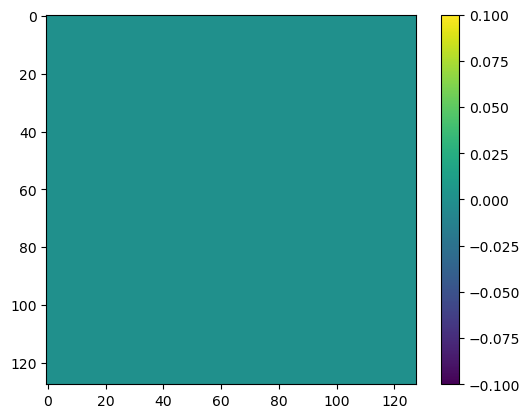

In [5]:
# The copy above must reproduce the mock observation of data/ (src/model.py, scripts/gen_mock_data.py):
# true gains, true sky (settings.TRUE_PW, seed TRUE_FIELD_SEED), no beam-centre source in the science field.
cfg_obs = SimulationConfig(shape=config.shape, BoxSize=config.BoxSize, nant=config.nant,
                           prefactor=settings.SCIENCE_FOREGROUND_FLUX, padded=padded, subsetindex=subsetindex)
true_z = torch.tensor(np.load(ROOT / 'data/true_z.npy'))
samples_obs = torch.cat([true_z, torch.zeros(1, 2 * settings.KNOWN_ANT)], dim=1)
lA, n1_t, n2_t, lkb = settings.TRUE_PW
res_obs = BrightnessTemperatureSimulation(cfg_obs).run_simulation(
    samples_obs, A=torch.tensor([10 ** lA]), n=torch.tensor([n1_t]), n2=torch.tensor([n2_t]),
    k_break=torch.tensor([10 ** lkb]), plot=False)

x_obs = torch.tensor(np.load(ROOT / 'data/x_obs.npy'))
diff = torch.abs(res_obs['normed_tracked_uv'][0].cpu() - x_obs)
print(f"max |δ - data/true_delta.npy| = {np.abs(res_obs['delta'][0].cpu().numpy() - np.load(ROOT / 'data/true_delta.npy')[0]).max():.2e}")
print(f'max |x - data/x_obs.npy|      = {diff.max():.2e}   (max |x| = {x_obs.abs().max():.2e})')
mock_dev, run_dev = str(np.load(ROOT / 'data/mock_device.npy')), torch.device(config.device).type
print(f'data/ made on {mock_dev}, this run on {run_dev}'
      + ('' if mock_dev == run_dev else ' -> the seeded field differs between CPU and GPU, so a non-zero difference is expected'))
plt.imshow(np.fft.fftshift(diff[0].numpy()))
plt.colorbar()

In [6]:
vref = np.load(ROOT / 'data/V_ref_obs.npy')
vref[0,1]

np.complex64(0.023327181+0.016970528j)

In [7]:
padded[0][2]

tensor([ 18., 113., 115.,  42.,  83.,  29.,  80.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,
          0.,   0.,   0.,   0.])

In [8]:
# Dense path of baseline (0, 1): V_ref[0, 1] = g_0 S_ref[0, 1] conj(g_1), with S_ref[0, 1] the integration-
# weighted mean of the calibrator's ortho-FFT over the baseline's track (DC cell excluded), as SkyMatrixGenerator.
cal   = settings.CALIBRATOR_FLUX * gaussian_2d(config.shape, settings.CALIBRATOR_SIGMA)
uvcal = torch.fft.fft2(torch.fft.ifftshift(cal), norm='ortho')
xt, yt, tt = padded[0].cpu()
on    = (tt > 0) & ((xt != 0) | (yt != 0))
S01   = (tt[on] * uvcal[yt[on].long(), xt[on].long()]).sum() / tt[on].sum()
tz    = np.load(ROOT / 'data/true_z.npy')[0]
g1    = complex(1 + tz[0], tz[1])                      # antenna 1; g_0 = 1
print(f'g_0 S_01 conj(g_1) = {complex(S01) * np.conj(g1):.6f}    V_ref_obs[0, 1] = {vref[0, 1]:.6f}')

g_0 S_01 conj(g_1) = 0.023327+0.016971j    V_ref_obs[0, 1] = 0.023327+0.016971j


In [9]:
# the track of baseline (0, 1): UV pixel u (column), v (row) and 30-s integrations per sample
torch.stack([xt[on], yt[on], tt[on]])

tensor([[  8.,   8.,   8.,   8.,   7.,   7.,   6.],
        [125., 124., 123., 122., 122., 121., 121.],
        [ 18., 113., 115.,  42.,  83.,  29.,  80.]])

Generate images for gain = 1+random number

In [10]:

sim = BrightnessTemperatureSimulation(config)
B=2
torch.manual_seed(42)
nant = config.nant   # 307 (AA*)
cols = 2 * (nant - 1)
knownant = settings.KNOWN_ANT      # as the pipeline: 106 unknown antennas
zeros = torch.zeros((B**2, int(knownant*2)))
    # Concatenate along the feature dimension (dim=1)
z = torch.randn((B**2, int(cols-knownant*2)))*settings.TRUE_Z_SCALE   # spread of the mock truth
samples = torch.cat([z, zeros], dim=1)

A = torch.linspace(0.0,0.0,B)
n = torch.linspace(-2.5,-2.5,B)

# Create all combinations
A_grid, n_grid = torch.meshgrid(A, n, indexing='ij')

# Flatten to 9x1 tensors
a_flat = A_grid.reshape(-1, 1).squeeze(1)
n_flat = n_grid.reshape(-1, 1).squeeze(1)

results41full = sim.run_simulation(samples, A=a_flat, n=n_flat, plot=False)

df41full = results41full["final_map"]
x41full = torch.fft.fftshift(torch.fft.ifft2(results41full["normed_tracked_uv"], norm='ortho'), dim=(-2, -1))

Pltting df field

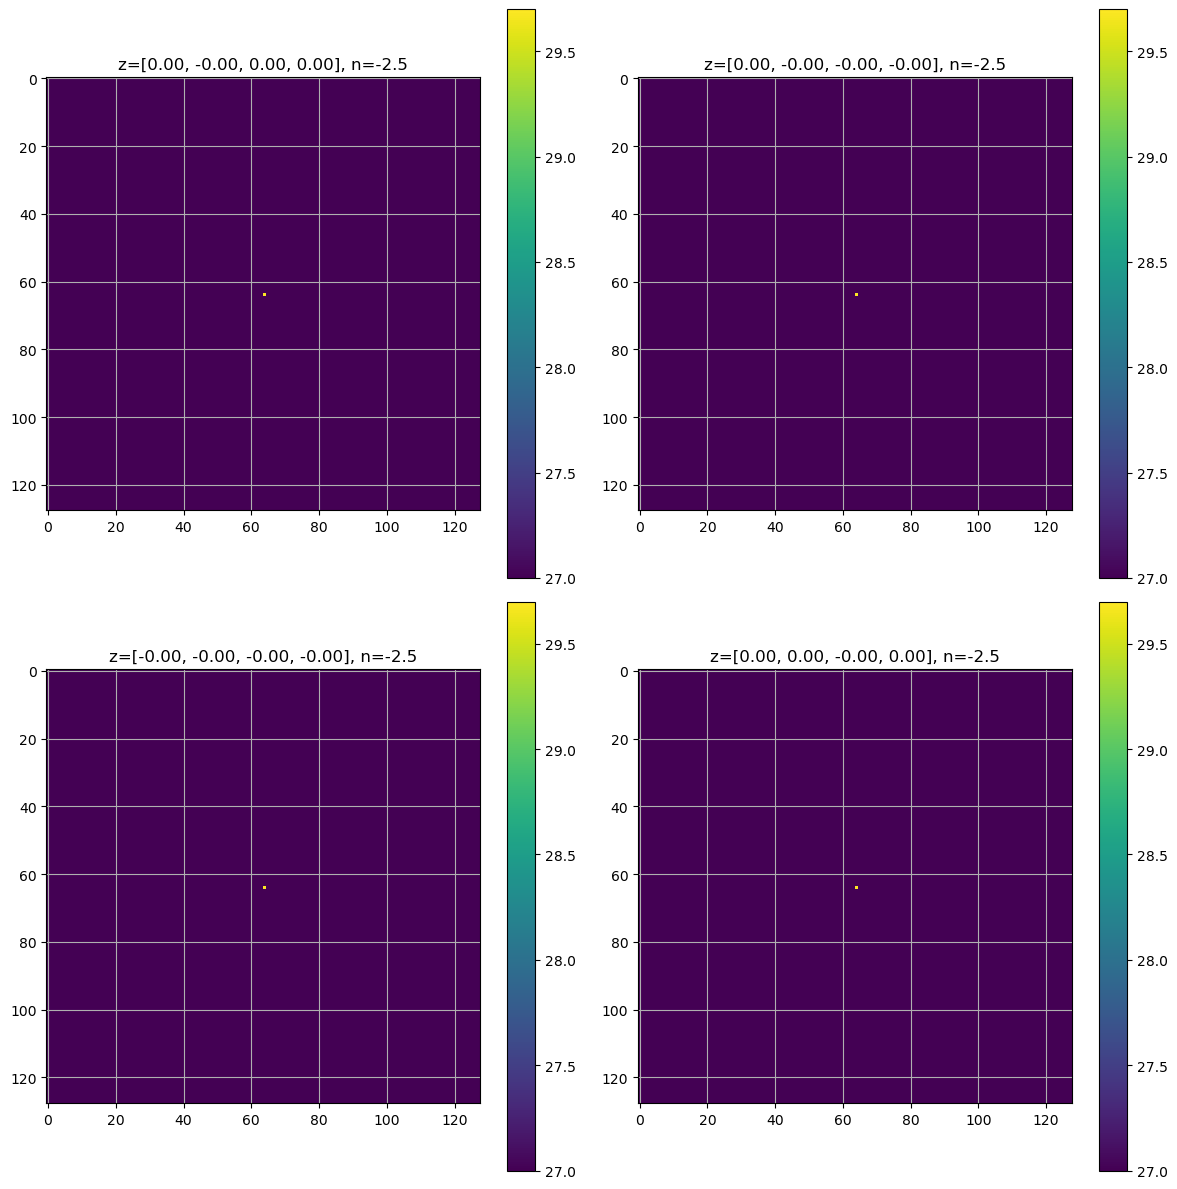

In [11]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(df40full[i])
    z_val = z40[i, :4]  # first 4 z values of this run

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

Pltting calibrated antennae images

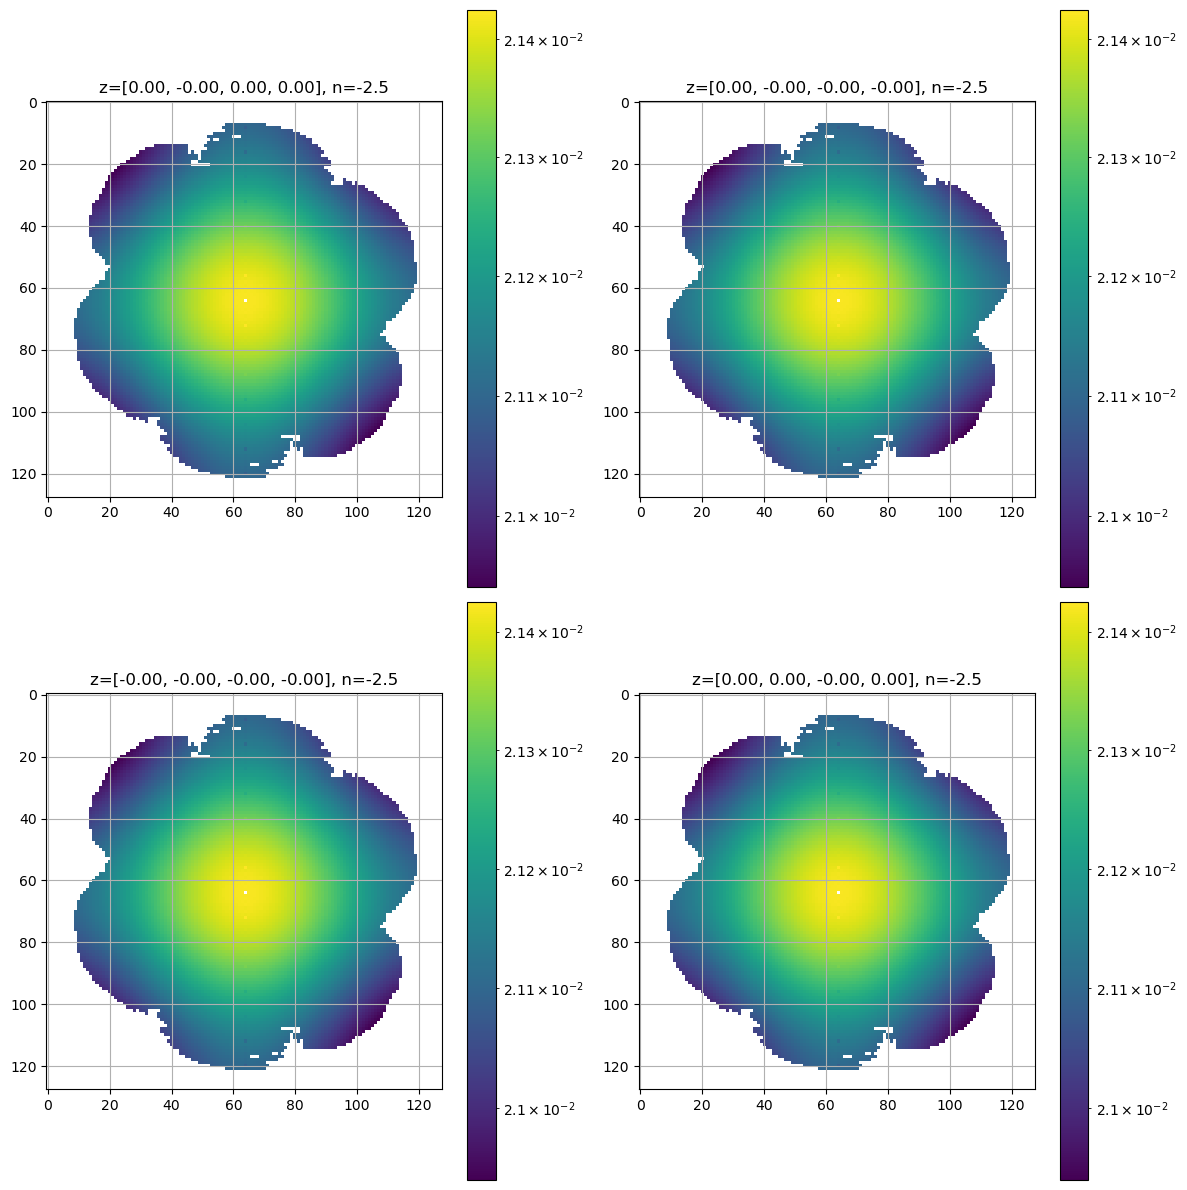

In [12]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))

for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()

    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(np.fft.fftshift(torch.abs(results40full["normed_tracked_uv"][i,0]).cpu().numpy()), norm=LogNorm())
    z_val = z40[i, :4]  # first 4 z values of this run

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

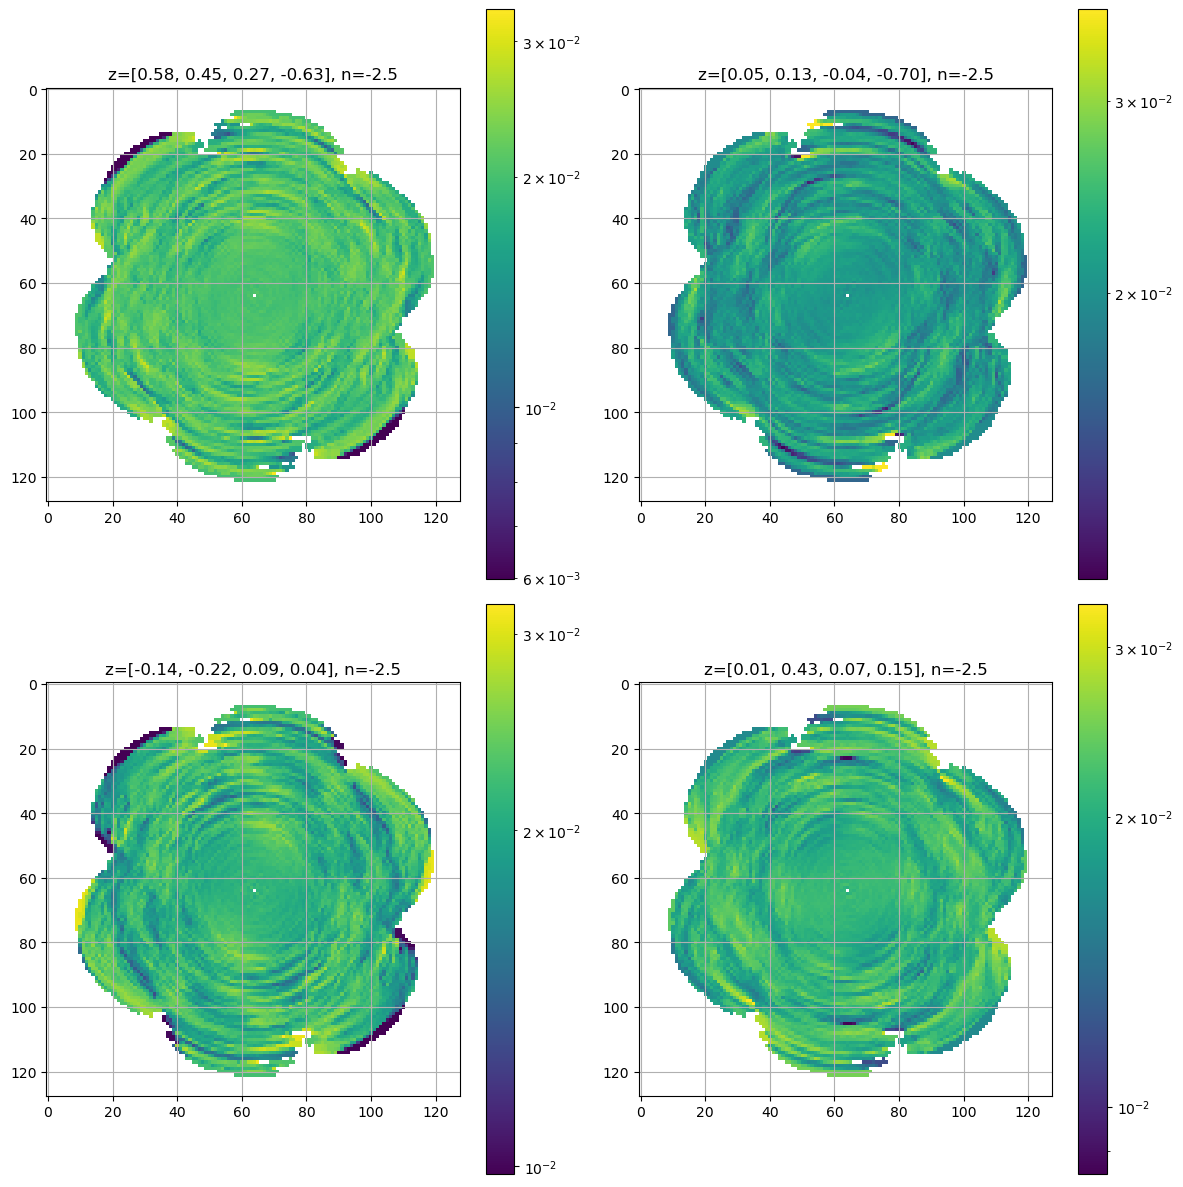

In [13]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))

for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()

    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(np.fft.fftshift(torch.abs(results41full["normed_tracked_uv"][i,0]).cpu().numpy()), norm=LogNorm())
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

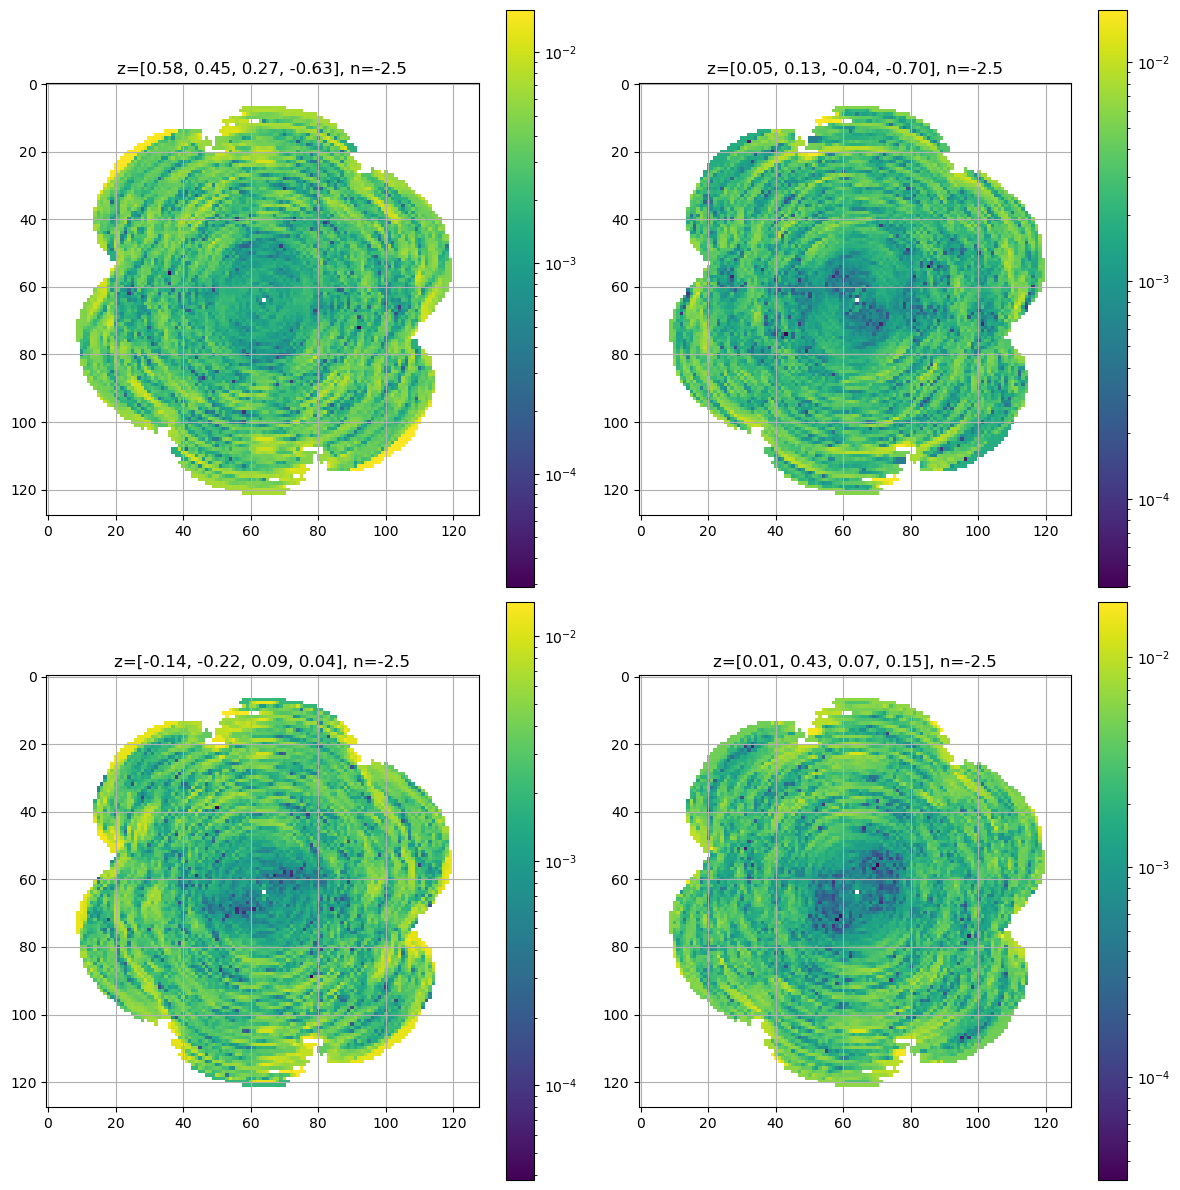

In [14]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))

for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()

    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(np.fft.fftshift(torch.abs(results40full["normed_tracked_uv"][i,0]-results41full["normed_tracked_uv"][i,0]).cpu().numpy()), norm=LogNorm())
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

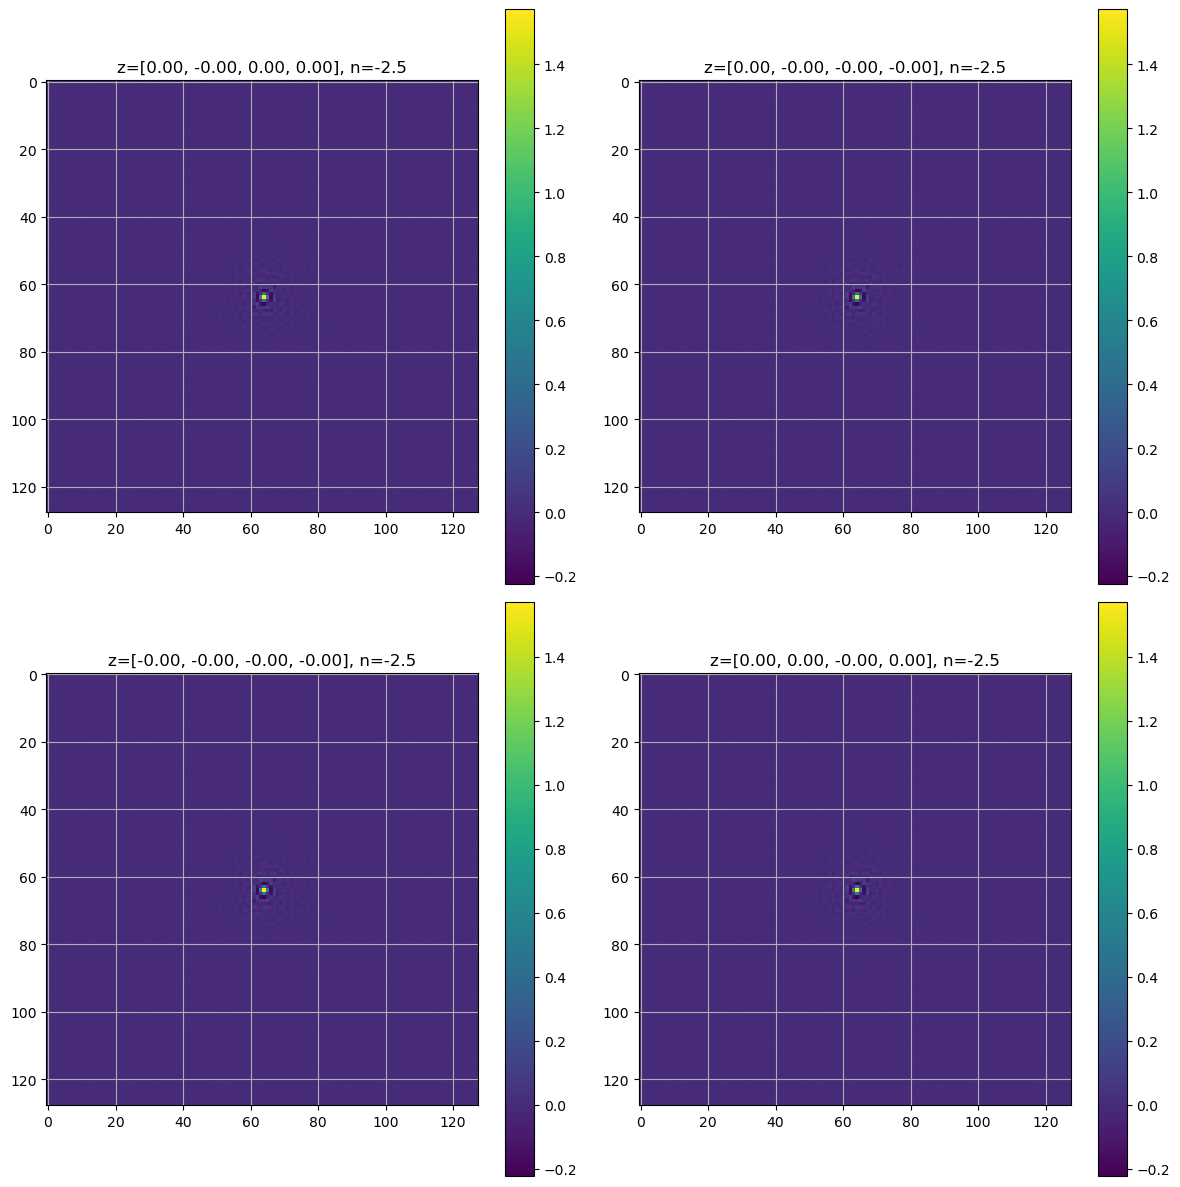

In [15]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x40full[i,0]))
    z_val = z40[i, :4]  # first 4 z values of this run

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

Plotting random antennae images

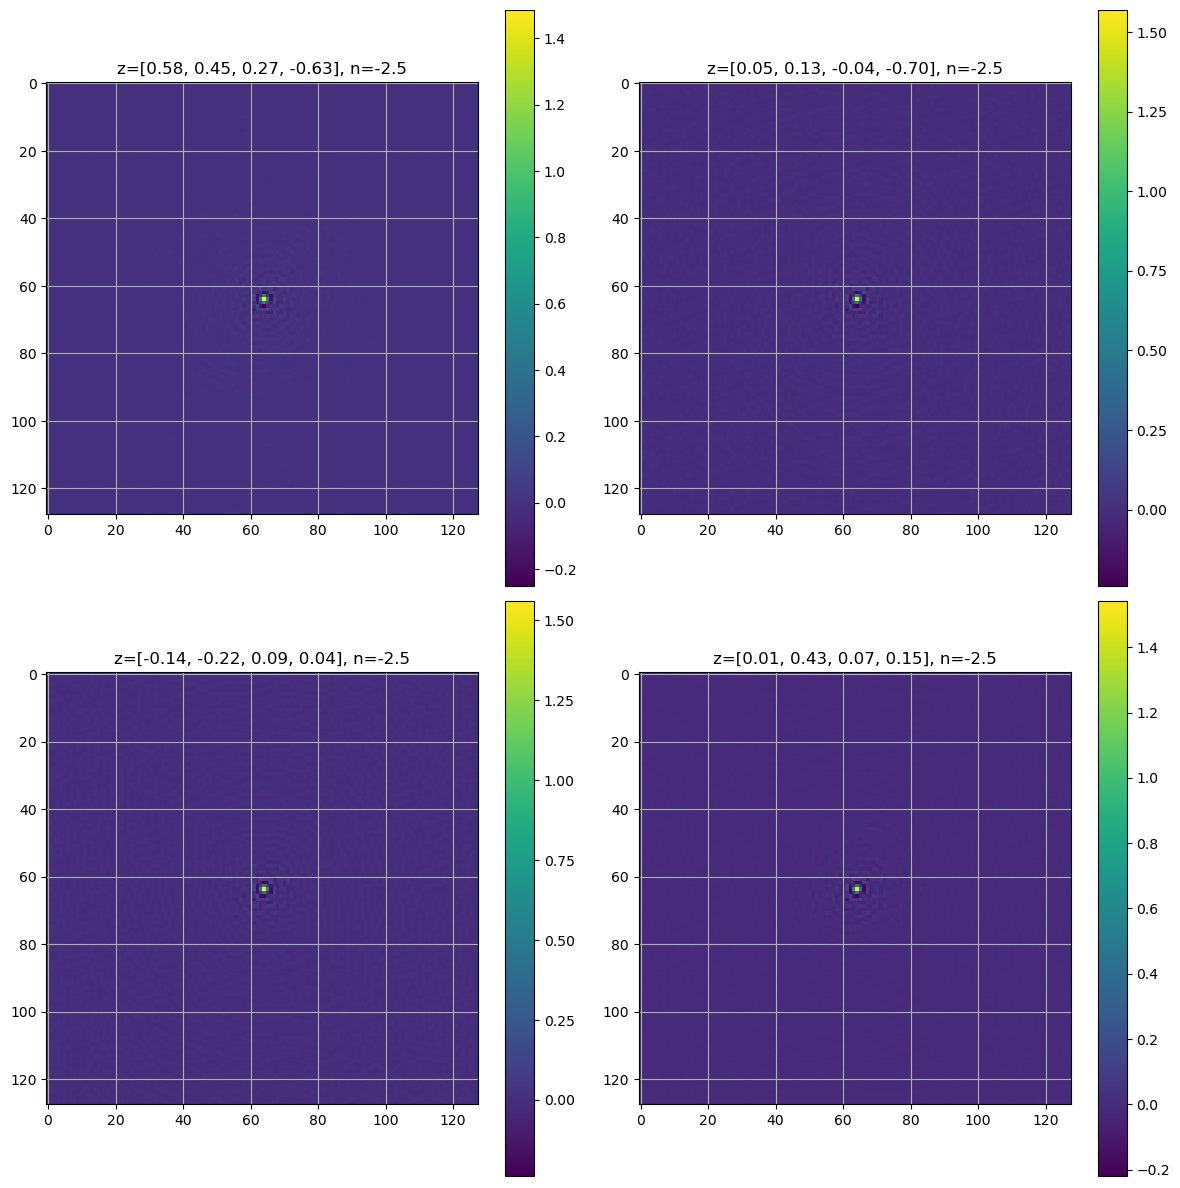

In [16]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x41full[i,0]))
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

Plotting difference images

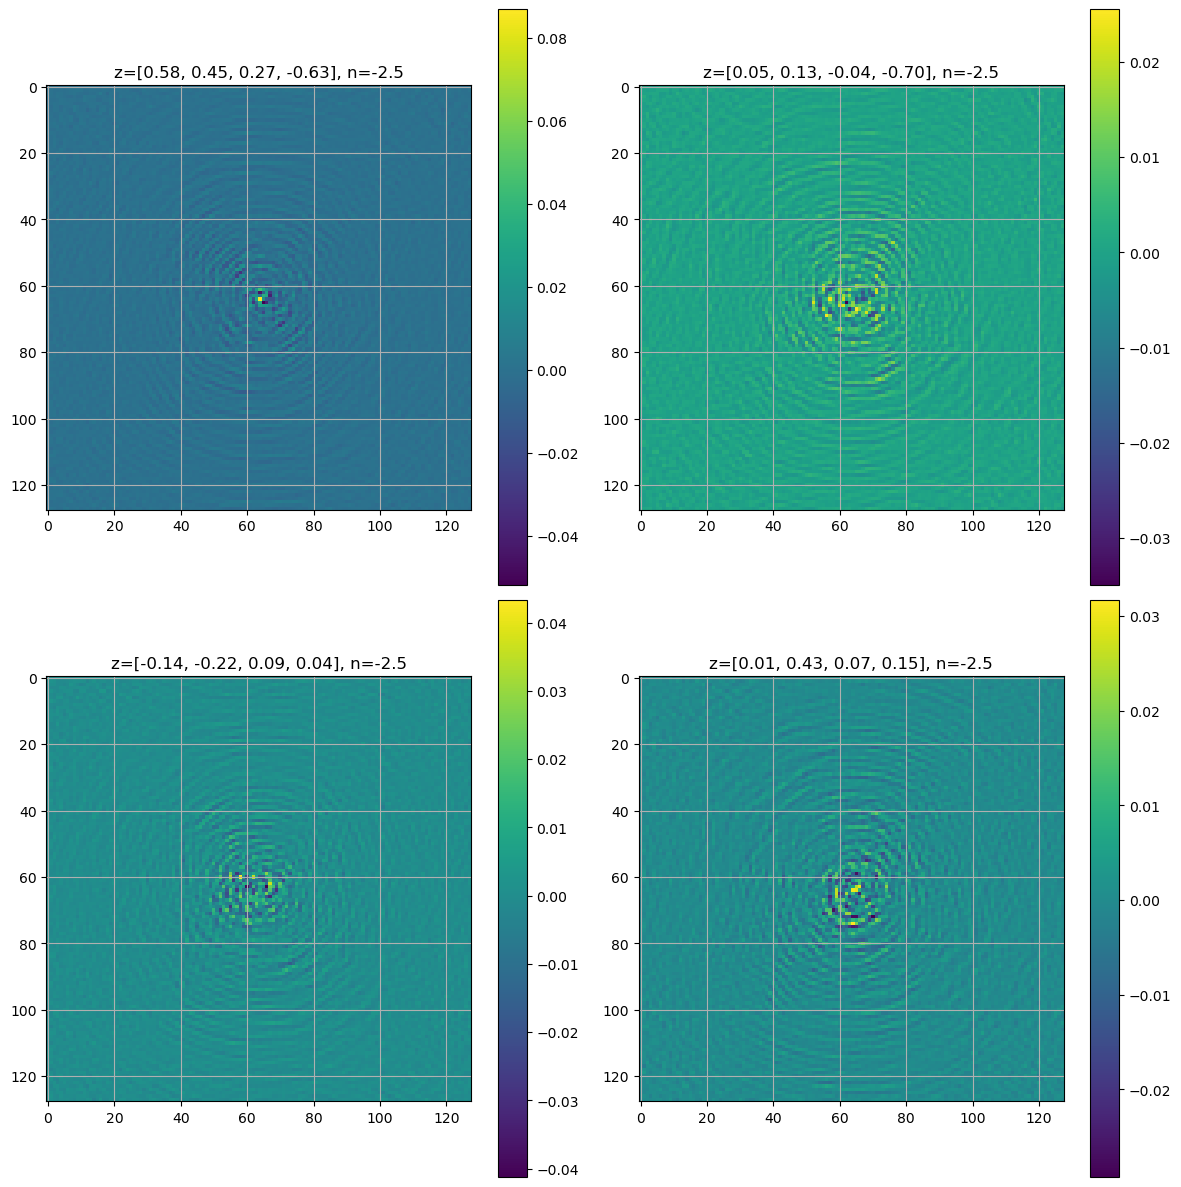

In [17]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x40full[i,0]-x41full[i,0]))
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

2 antennae case (antennas 1–2 free, all others g = 1)

In [18]:

sim = BrightnessTemperatureSimulation(config)
B=2
torch.manual_seed(42)
nant = config.nant   # 307 (AA*)
cols = 2 * (nant - 1)
knownant = nant - 1 - 2      # 2 free antennas (1, 2); all others known, g = 1
zeros = torch.zeros((B**2, int(knownant*2)))
    # Concatenate along the feature dimension (dim=1)
z = torch.randn((B**2, int(cols-knownant*2)))*0
samples = torch.cat([z, zeros], dim=1)
z20 = z.clone()      # z of this run, for its plot titles

A = torch.linspace(0.0,0.0,B)
n = torch.linspace(-2.5,-2.5,B)

# Create all combinations
A_grid, n_grid = torch.meshgrid(A, n, indexing='ij')

# Flatten to 9x1 tensors
a_flat = A_grid.reshape(-1, 1).squeeze(1)
n_flat = n_grid.reshape(-1, 1).squeeze(1)

results20full = sim.run_simulation(samples, A=a_flat, n=n_flat, plot=False)

df20full = results20full["final_map"]
x20full = torch.fft.fftshift(torch.fft.ifft2(results20full["normed_tracked_uv"], norm='ortho'), dim=(-2, -1))

In [19]:

sim = BrightnessTemperatureSimulation(config)
B=2
torch.manual_seed(42)
nant = config.nant   # 307 (AA*)
cols = 2 * (nant - 1)
knownant = nant - 1 - 2      # 2 free antennas (1, 2); all others known, g = 1
zeros = torch.zeros((B**2, int(knownant*2)))
    # Concatenate along the feature dimension (dim=1)
z = torch.randn((B**2, int(cols-knownant*2)))*1
samples = torch.cat([z, zeros], dim=1)

A = torch.linspace(0.0,0.0,B)
n = torch.linspace(-2.5,-2.5,B)

# Create all combinations
A_grid, n_grid = torch.meshgrid(A, n, indexing='ij')

# Flatten to 9x1 tensors
a_flat = A_grid.reshape(-1, 1).squeeze(1)
n_flat = n_grid.reshape(-1, 1).squeeze(1)

results21full = sim.run_simulation(samples, A=a_flat, n=n_flat, plot=False)

df21full = results21full["final_map"]
x21full = torch.fft.fftshift(torch.fft.ifft2(results21full["normed_tracked_uv"], norm='ortho'), dim=(-2, -1))

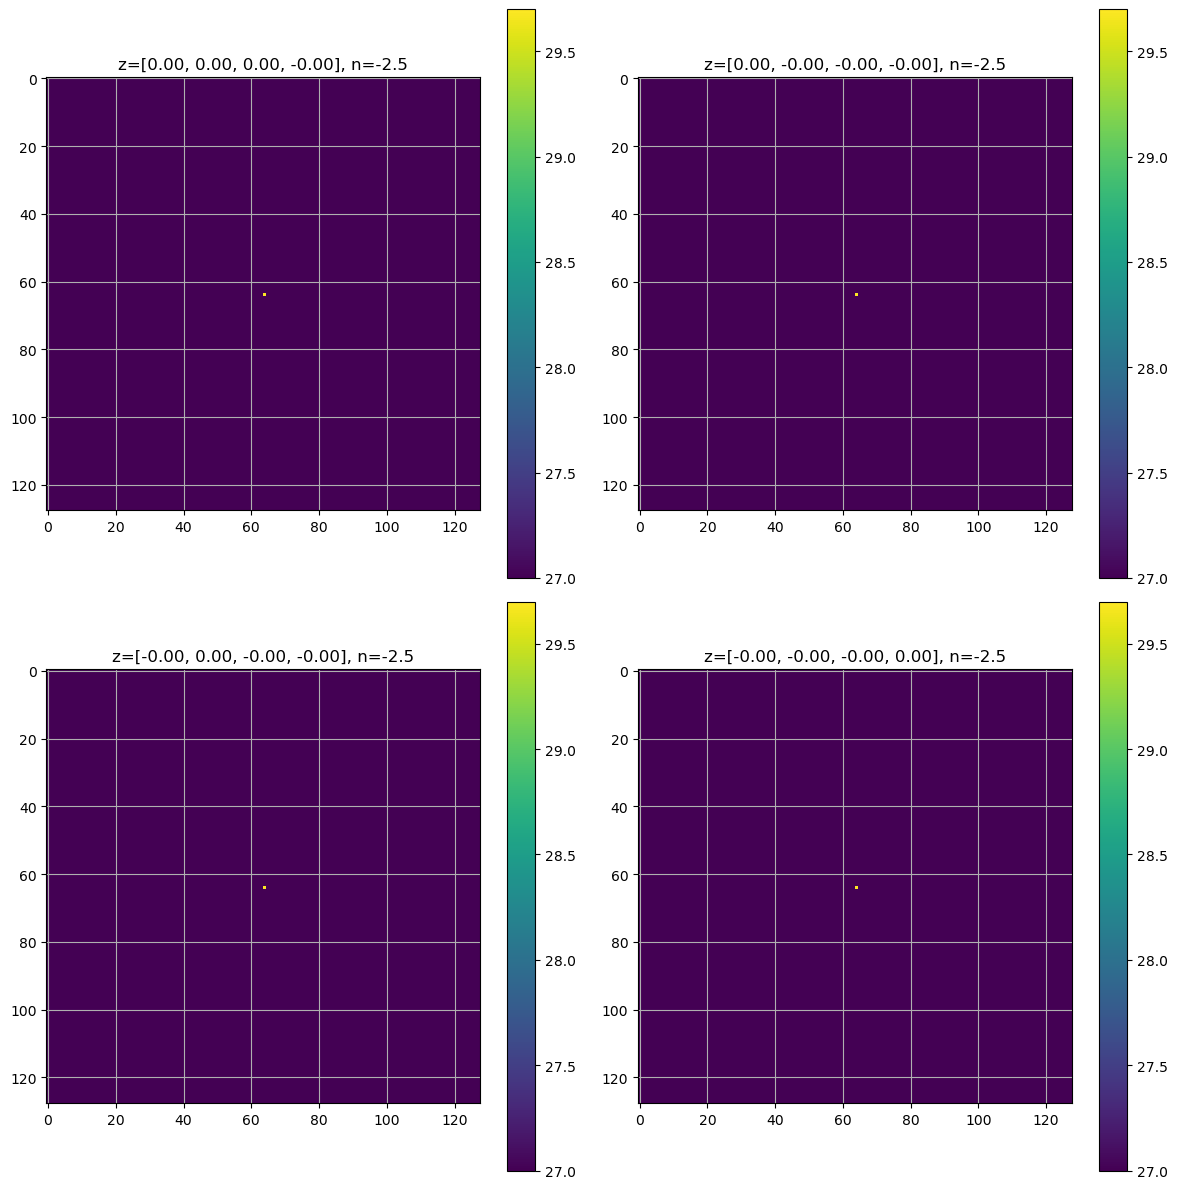

In [20]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(df20full[i])
    z_val = z20[i, :4]  # first 4 z values of this run

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

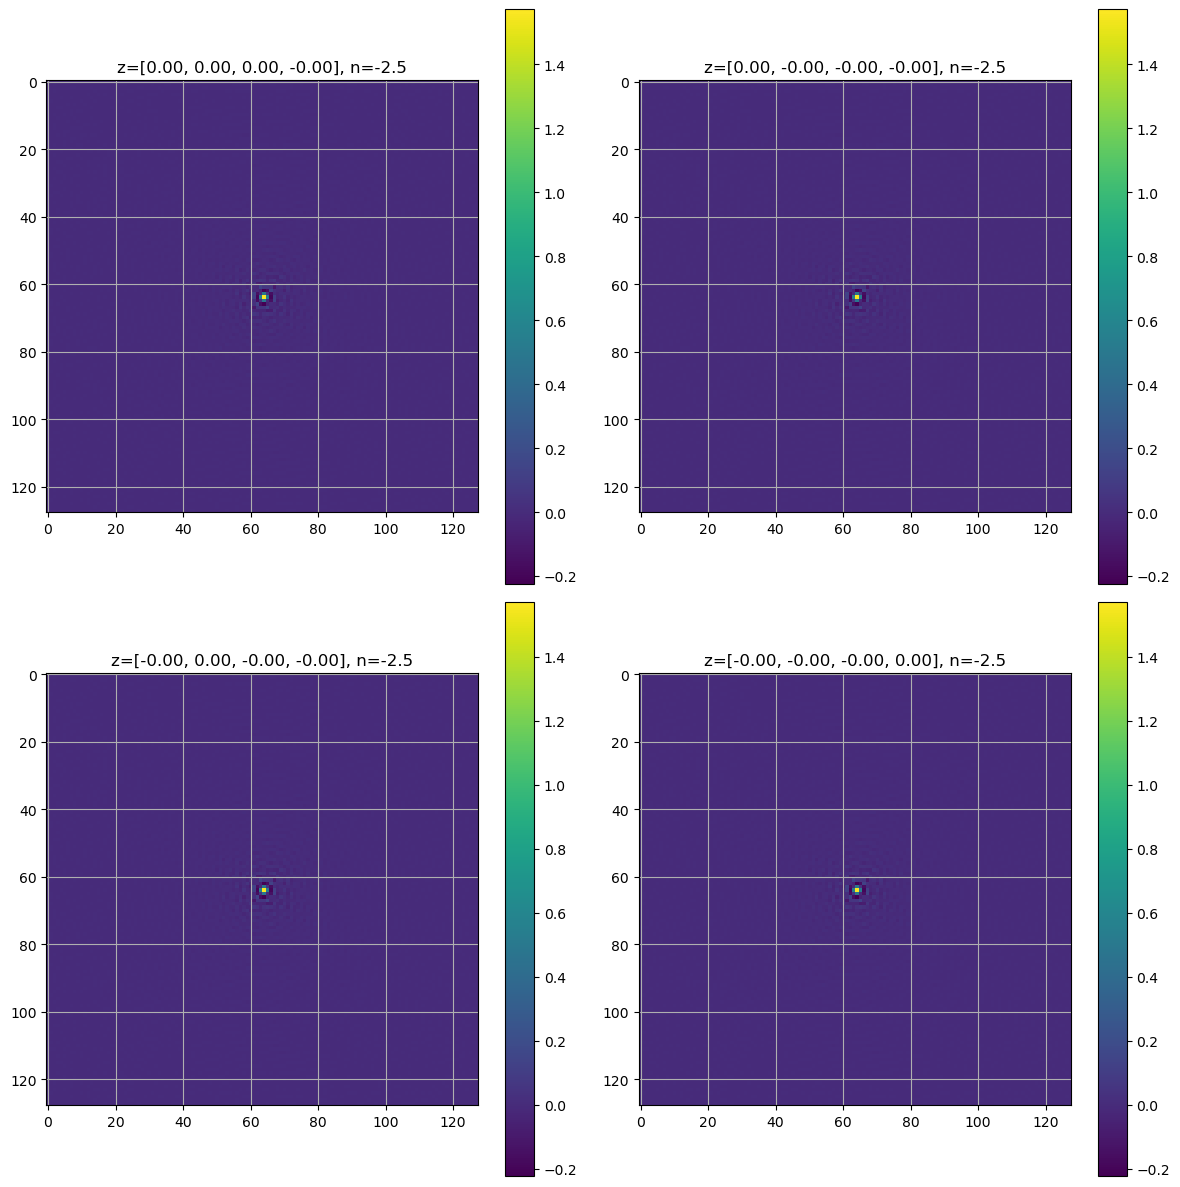

In [21]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x20full[i,0]))
    z_val = z20[i, :4]  # first 4 z values of this run

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

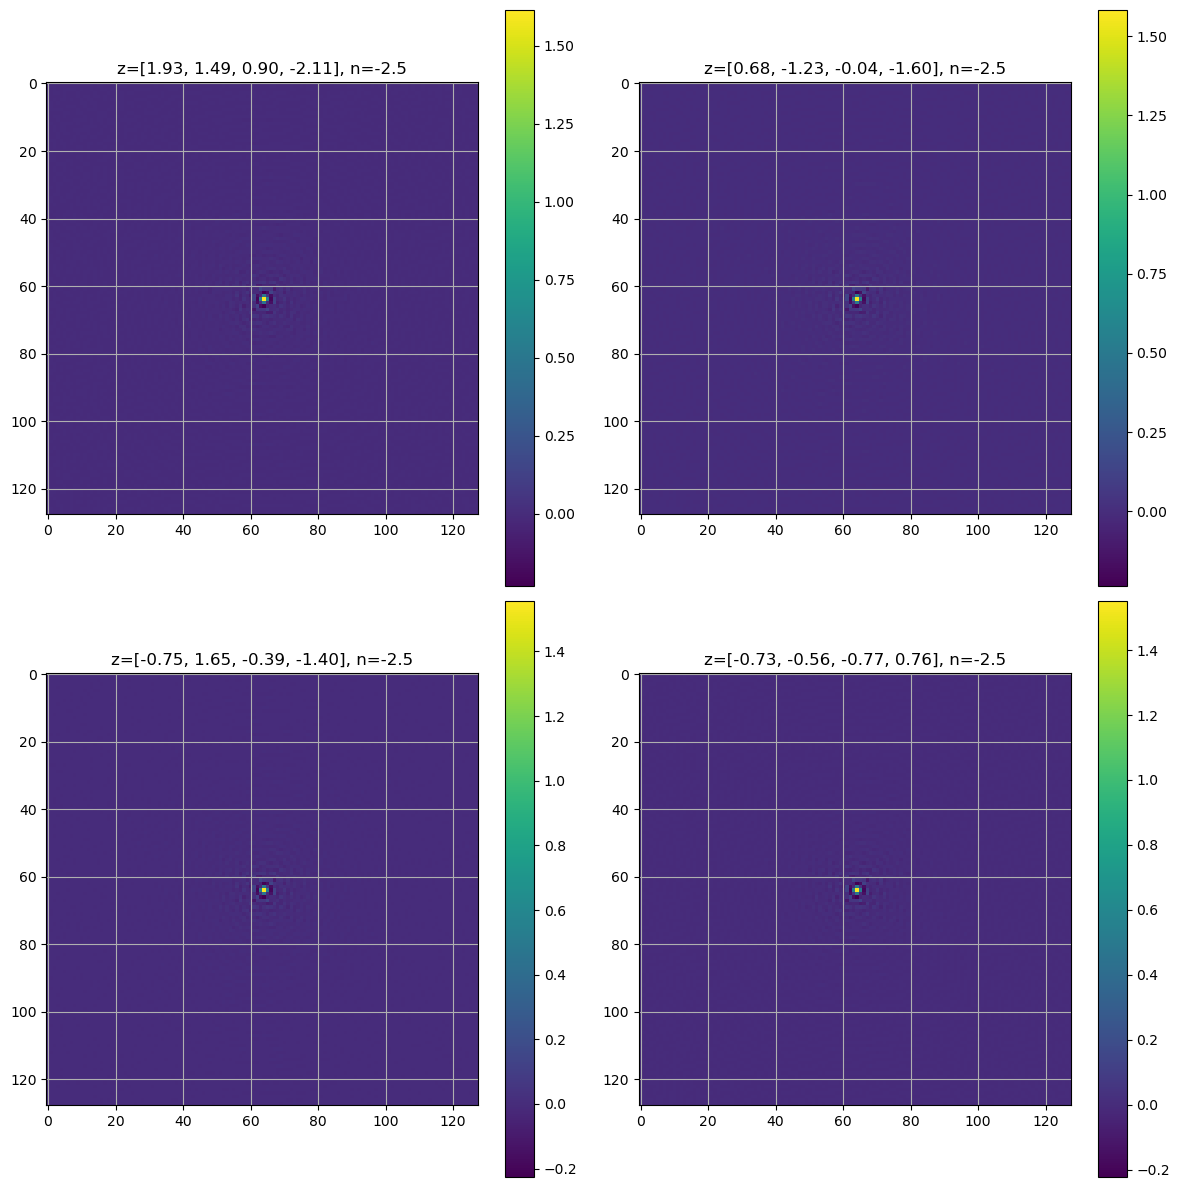

In [22]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x21full[i,0]))
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

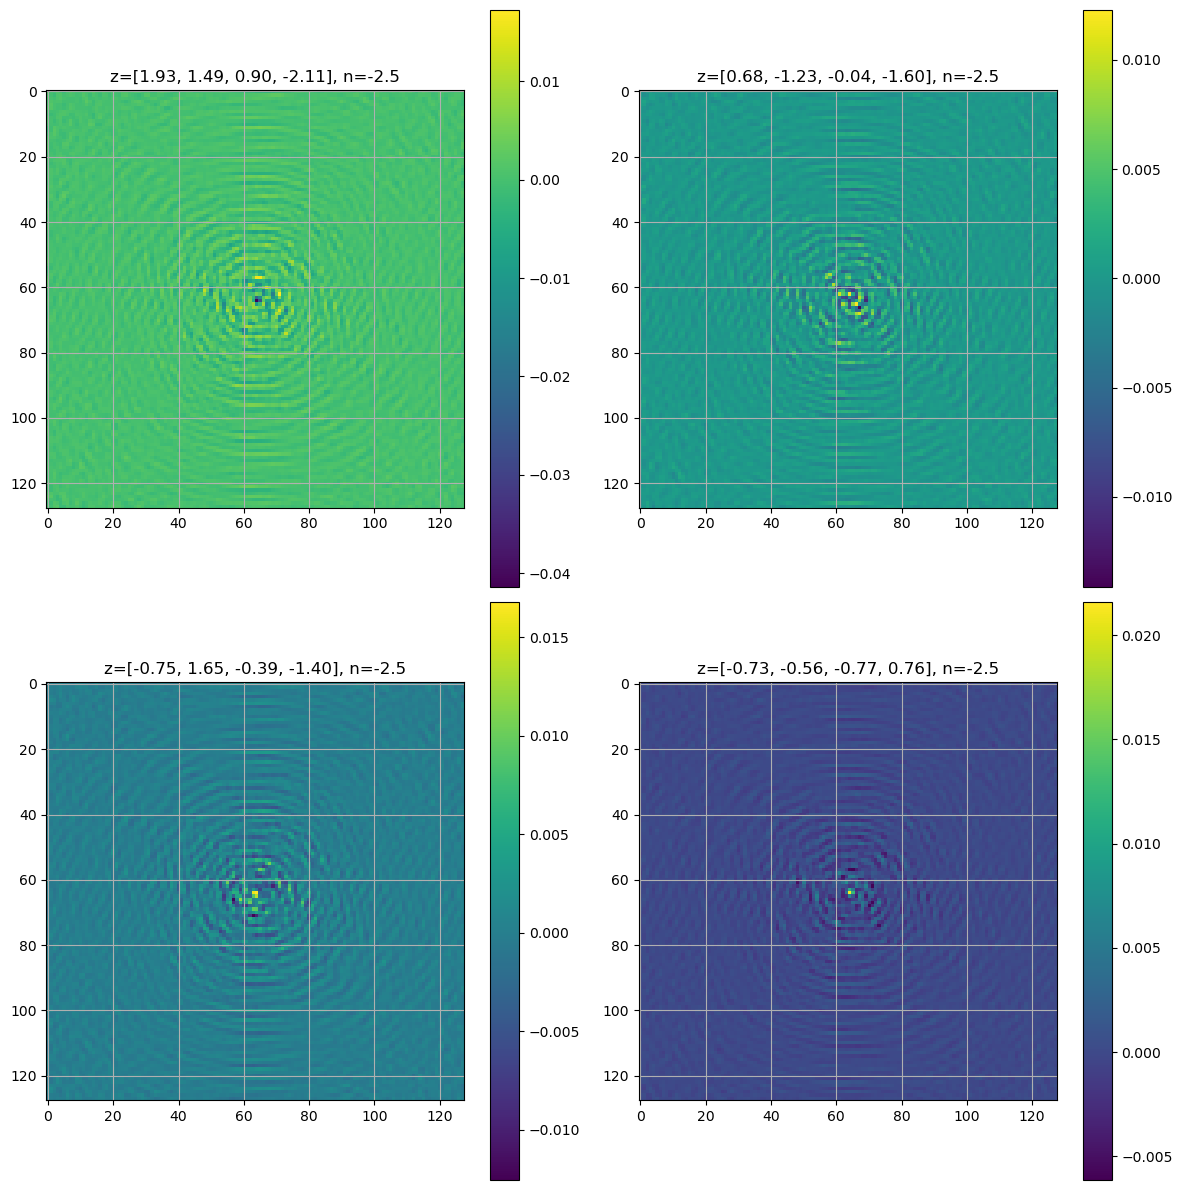

In [23]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x20full[i,0]-x21full[i,0]))
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

0 for other antennae: antennas 0–10 switched on (cell 32, g = 1) or 0–2 (cell 36, random g); all others g = 0

In [24]:

sim = BrightnessTemperatureSimulation(config)
B=2
torch.manual_seed(42)
nant = config.nant   # 307 (AA*)
cols = 2 * (nant - 1)
knownant = nant - 1 - 10     # antennas 1–10 on, all others switched off below
zeros = torch.zeros((B**2, int(knownant * 2)))
zeros[:, ::2] = -1
    # Concatenate along the feature dimension (dim=1)
z = torch.randn((B**2, int(cols-knownant*2)))*0
samples = torch.cat([z, zeros], dim=1)

A = torch.linspace(0.0,0.0,B)
n = torch.linspace(-2.5,-2.5,B)

# Create all combinations
A_grid, n_grid = torch.meshgrid(A, n, indexing='ij')

# Flatten to 9x1 tensors
a_flat = A_grid.reshape(-1, 1).squeeze(1)
n_flat = n_grid.reshape(-1, 1).squeeze(1)

results20empty = sim.run_simulation(samples, A=a_flat, n=n_flat, plot=False)

df20empty = results20empty["final_map"]
x20empty = torch.fft.fftshift(torch.fft.ifft2(results20empty["normed_tracked_uv"], norm='ortho'), dim=(-2, -1))

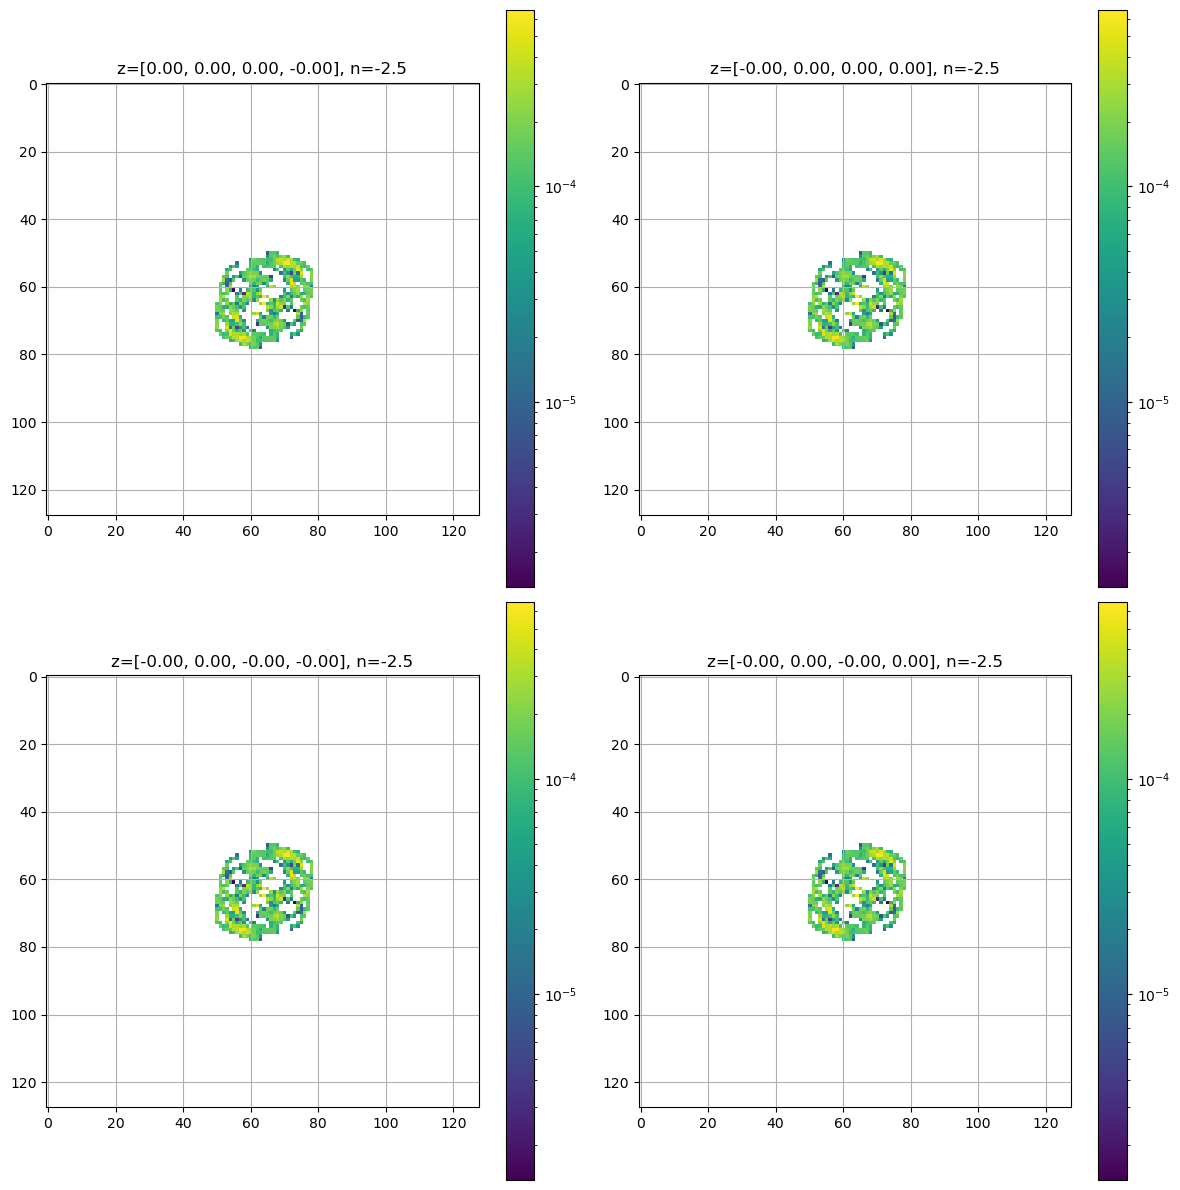

In [25]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))

for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()

    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(np.fft.fftshift(torch.abs(results20empty["normed_tracked_uv"][i,0]).cpu().numpy()), norm=LogNorm())
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

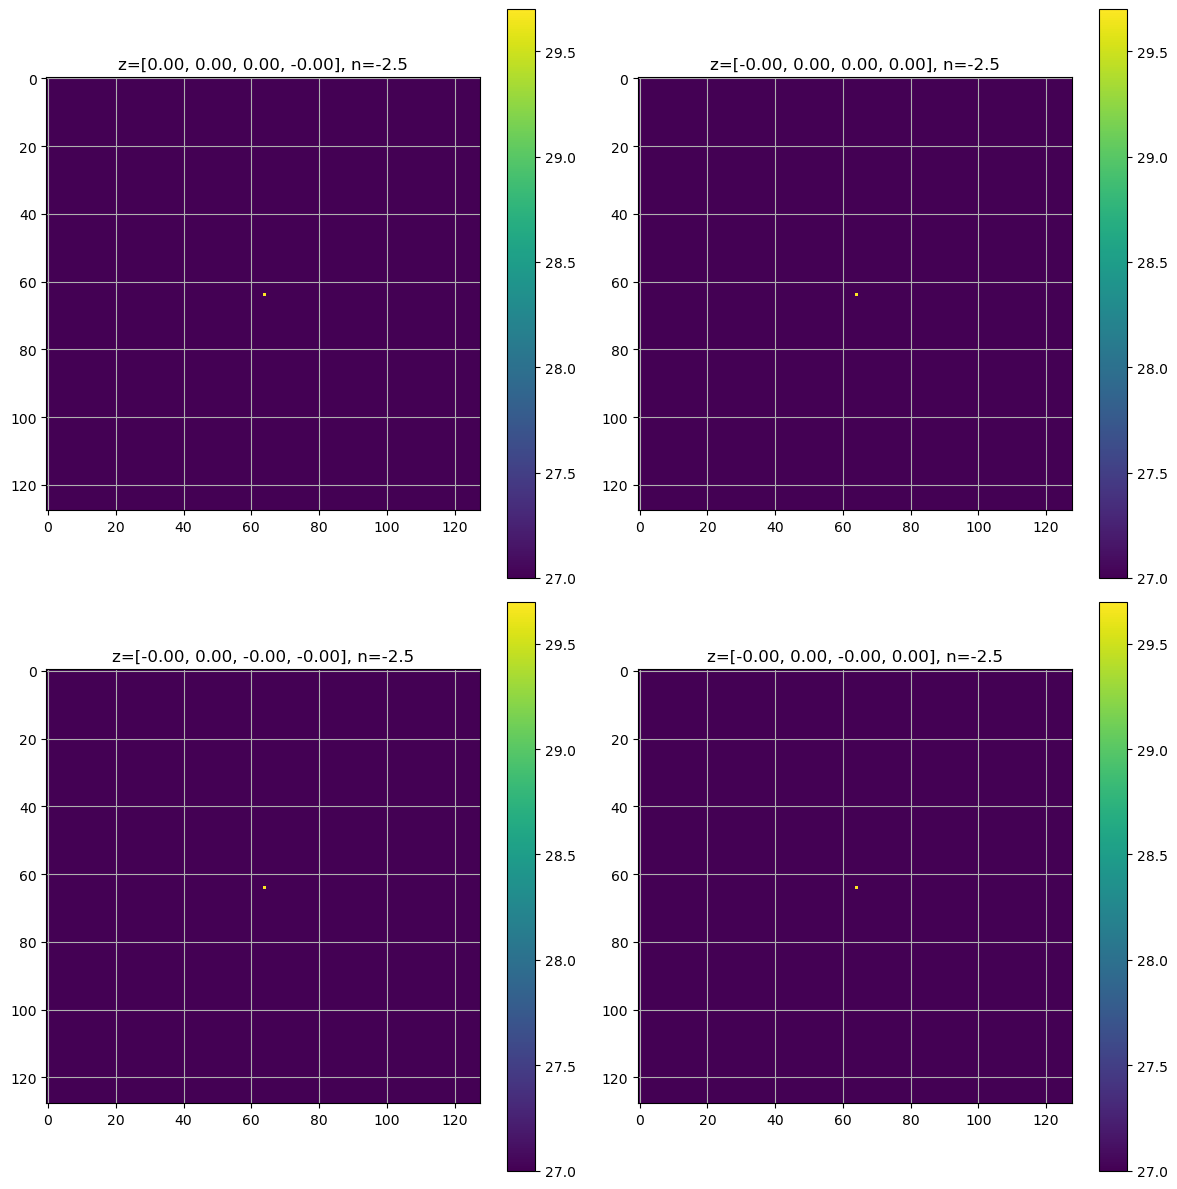

In [26]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(df20empty[i])
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

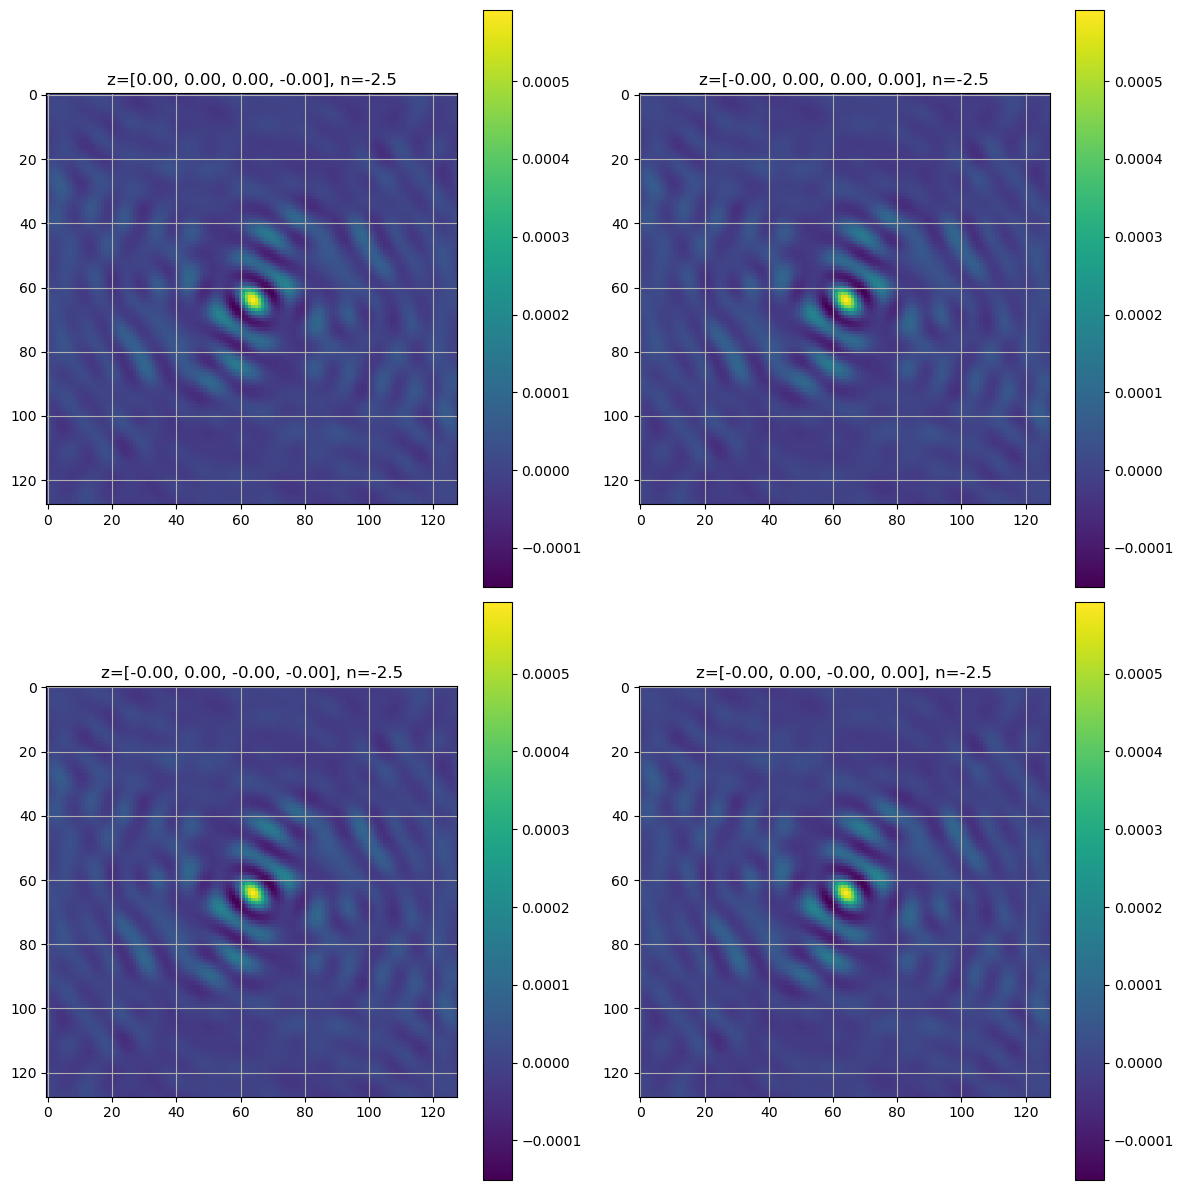

In [27]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x20empty[i,0]))
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

In [28]:

sim = BrightnessTemperatureSimulation(config)
B=2
torch.manual_seed(42)
nant = config.nant   # 307 (AA*)
cols = 2 * (nant - 1)
knownant = nant - 1 - 2      # antennas 1–2 on, all others switched off below
zeros = torch.zeros((B**2, int(knownant * 2)))
zeros[:, ::2] = -1
    # Concatenate along the feature dimension (dim=1)
z = torch.randn((B**2, int(cols-knownant*2)))*1
samples = torch.cat([z, zeros], dim=1)

A = torch.linspace(0.0,0.0,B)
n = torch.linspace(-2.5,-2.5,B)

# Create all combinations
A_grid, n_grid = torch.meshgrid(A, n, indexing='ij')

# Flatten to 9x1 tensors
a_flat = A_grid.reshape(-1, 1).squeeze(1)
n_flat = n_grid.reshape(-1, 1).squeeze(1)

results21empty = sim.run_simulation(samples, A=a_flat, n=n_flat, plot=False)

df21empty = results21empty["final_map"]
x21empty = torch.fft.fftshift(torch.fft.ifft2(results21empty["normed_tracked_uv"], norm='ortho'), dim=(-2, -1))

In [29]:
results20empty["normed_tracked_uv"].shape

torch.Size([4, 2, 128, 128])

Earlier `MaskedFlatten` experiments were removed from this notebook: the version used for training is `MaskedFlatten` in `src/embedding.py` (mask from the non-zero positions of the first batch, not saved in the state dict), tested in `tests/test_pipeline.py`.

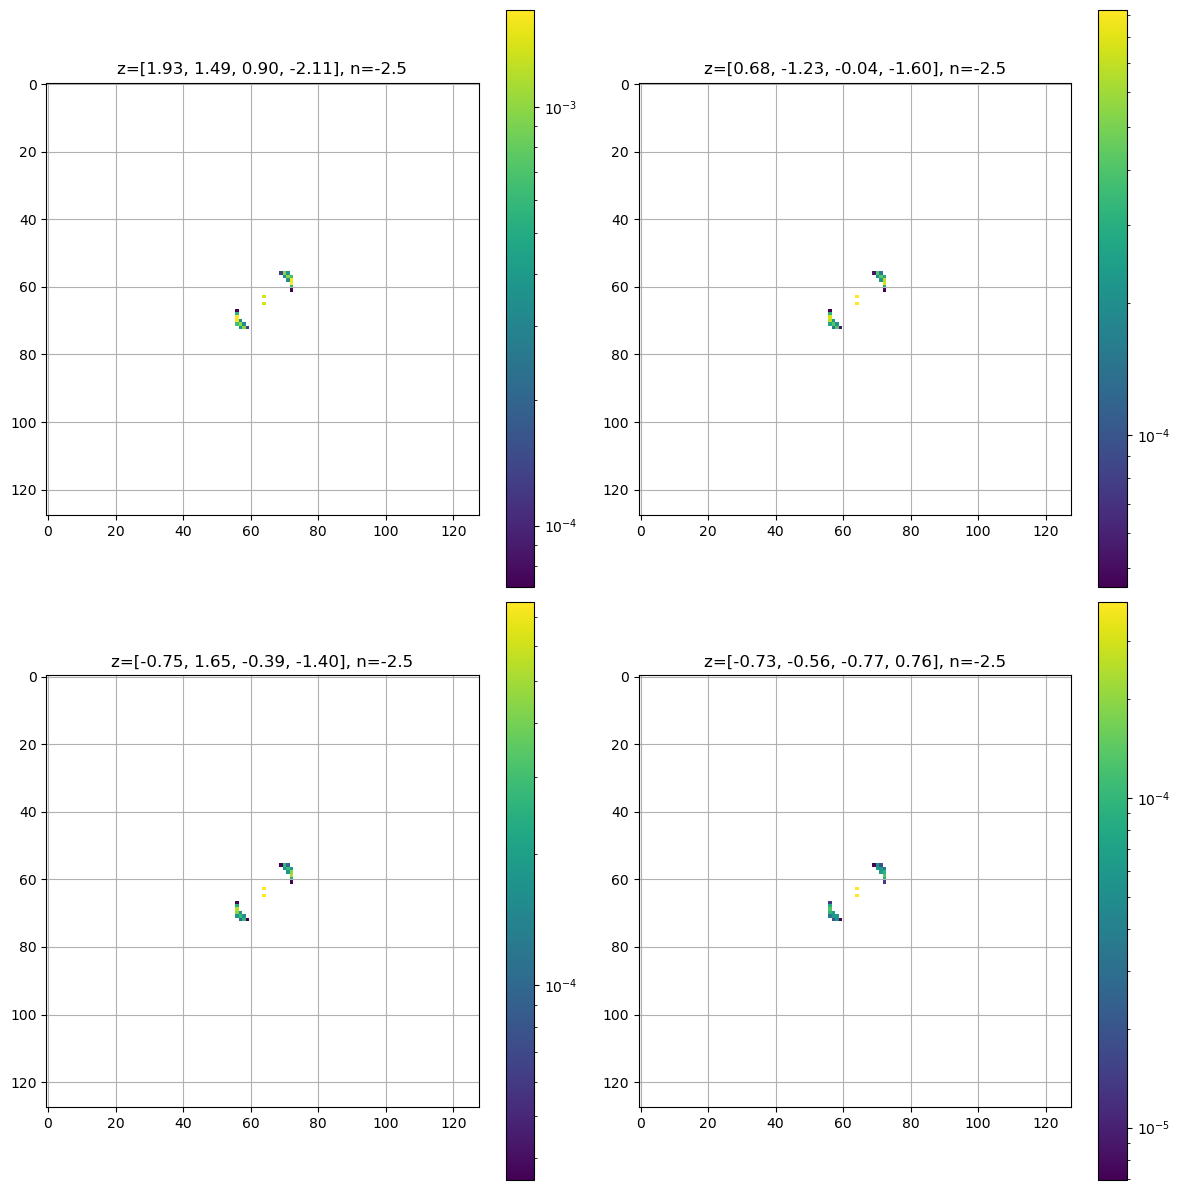

In [30]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))

for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()

    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(np.fft.fftshift(torch.abs(results21empty["normed_tracked_uv"][i,0]).cpu().numpy()), norm=LogNorm())
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

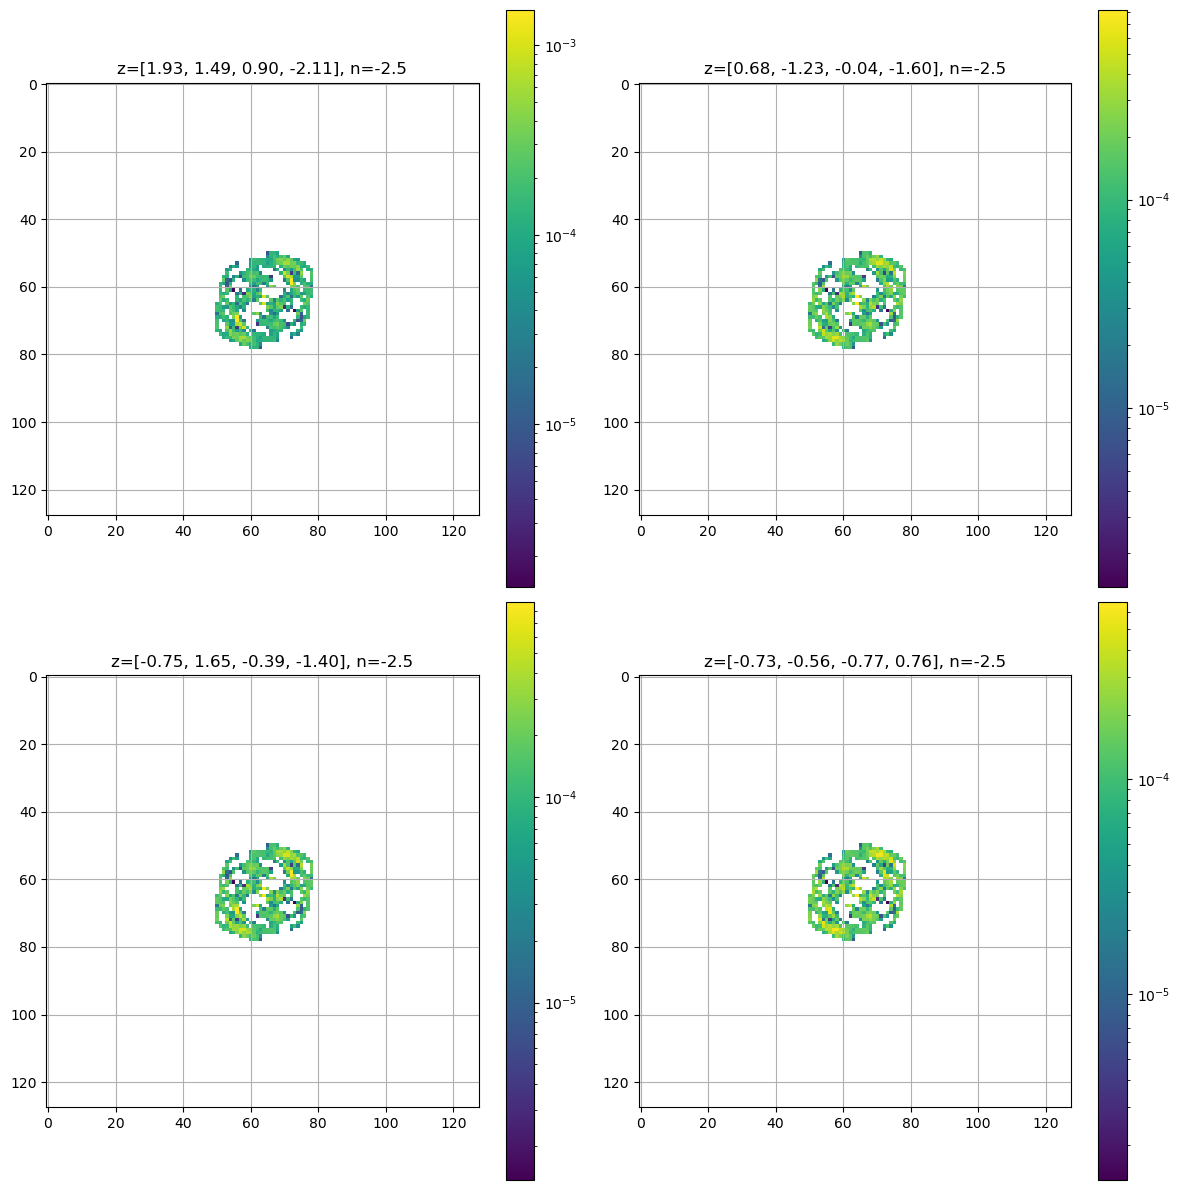

In [31]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))

for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()

    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(np.fft.fftshift(torch.abs(results20empty["normed_tracked_uv"][i,0]-results21empty["normed_tracked_uv"][i,0]).cpu().numpy()), norm=LogNorm())
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

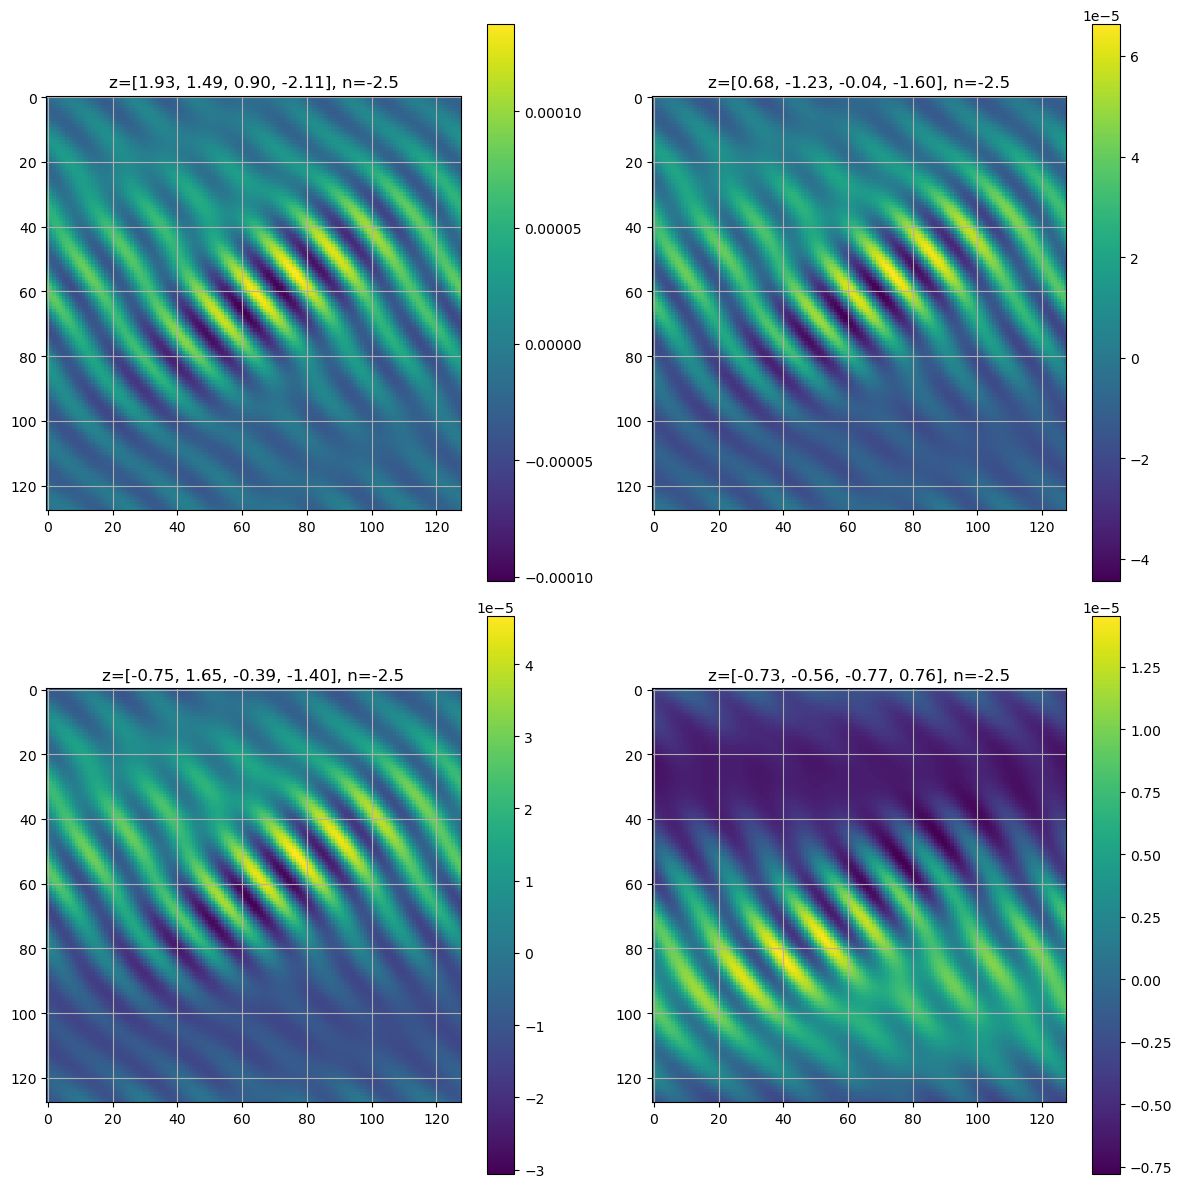

In [32]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x21empty[i,0]))
    # axes[row, col].set_title(f'z={z_val:.3f}, n={n_val:.1f}')
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

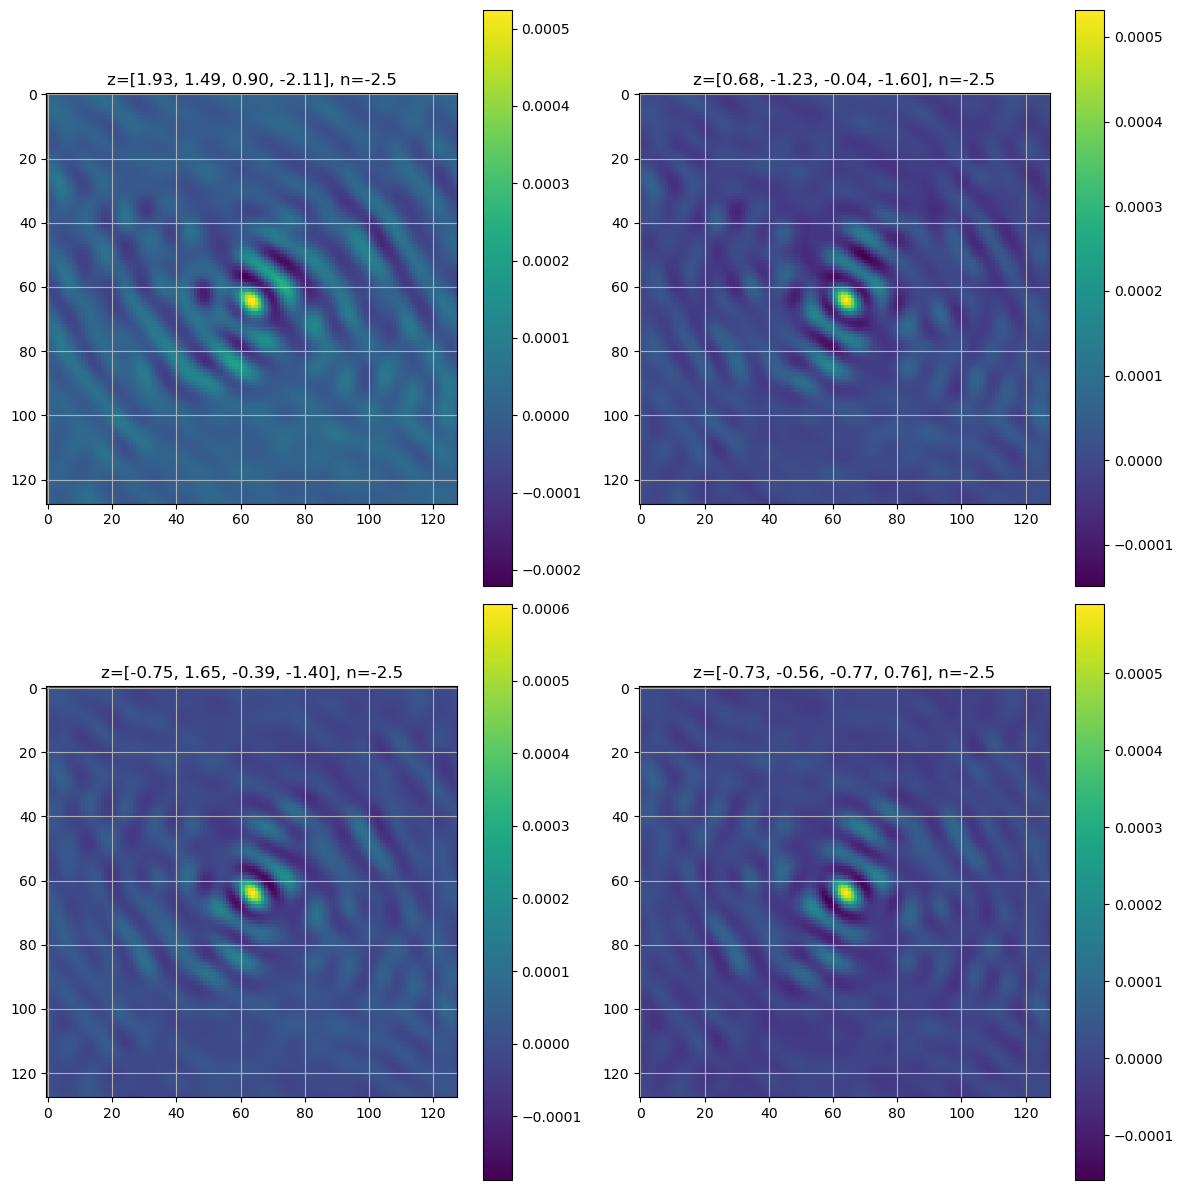

In [33]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x20empty[i,0]-x21empty[i,0]))
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

1 antenna case (antenna 1 free, all others g = 1)

In [34]:

sim = BrightnessTemperatureSimulation(config)
B=2
torch.manual_seed(42)
nant = config.nant   # 307 (AA*)
cols = 2 * (nant - 1)
knownant = nant - 1 - 1      # 1 free antenna (1); all others known, g = 1
zeros = torch.zeros((B**2, int(knownant*2)))
    # Concatenate along the feature dimension (dim=1)
z = torch.randn((B**2, int(cols-knownant*2)))*0
samples = torch.cat([z, zeros], dim=1)
z10 = z.clone()      # z of this run, for its plot titles

A = torch.linspace(0.0,0.0,B)
n = torch.linspace(-2.5,-2.5,B)

# Create all combinations
A_grid, n_grid = torch.meshgrid(A, n, indexing='ij')

# Flatten to 9x1 tensors
a_flat = A_grid.reshape(-1, 1).squeeze(1)
n_flat = n_grid.reshape(-1, 1).squeeze(1)

results10full = sim.run_simulation(samples, A=a_flat, n=n_flat, plot=False)

df10full = results10full["final_map"]
x10full = torch.fft.fftshift(torch.fft.ifft2(results10full["normed_tracked_uv"], norm='ortho'), dim=(-2, -1))

In [35]:

sim = BrightnessTemperatureSimulation(config)
B=2
torch.manual_seed(42)
nant = config.nant   # 307 (AA*)
cols = 2 * (nant - 1)
knownant = nant - 1 - 1      # 1 free antenna (1); all others known, g = 1
zeros = torch.zeros((B**2, int(knownant*2)))
    # Concatenate along the feature dimension (dim=1)
z = torch.randn((B**2, int(cols-knownant*2)))*1
samples = torch.cat([z, zeros], dim=1)

A = torch.linspace(0.0,0.0,B)
n = torch.linspace(-2.5,-2.5,B)

# Create all combinations
A_grid, n_grid = torch.meshgrid(A, n, indexing='ij')

# Flatten to 9x1 tensors
a_flat = A_grid.reshape(-1, 1).squeeze(1)
n_flat = n_grid.reshape(-1, 1).squeeze(1)

results11full = sim.run_simulation(samples, A=a_flat, n=n_flat, plot=False)

df11full = results11full["final_map"]
x11full = torch.fft.fftshift(torch.fft.ifft2(results11full["normed_tracked_uv"], norm='ortho'), dim=(-2, -1))

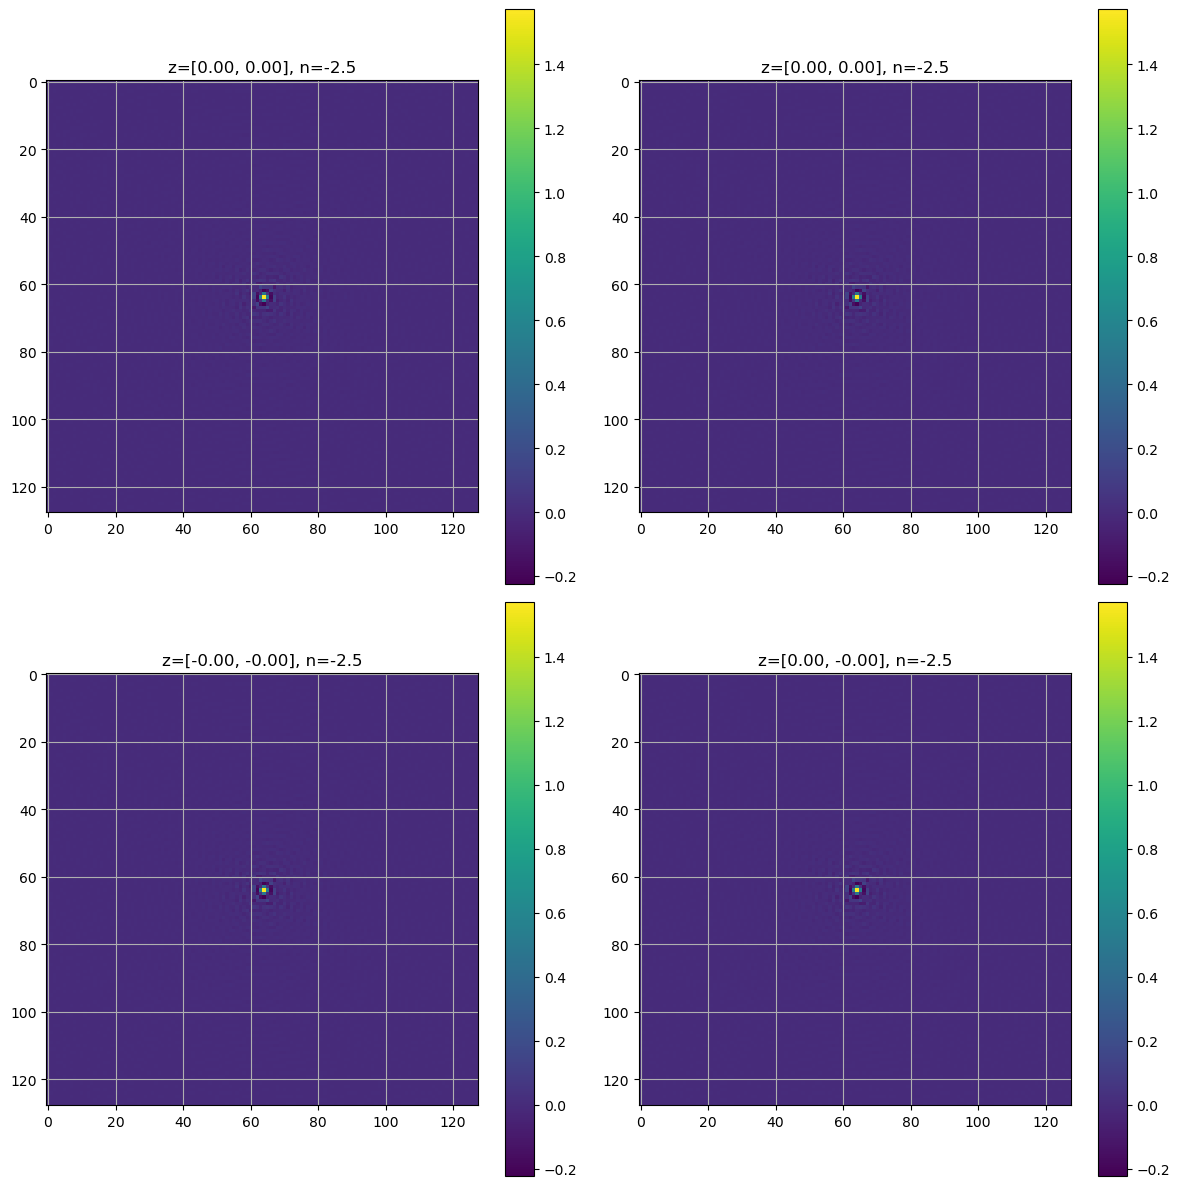

In [36]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x10full[i,0]))
    z_val = z10[i, :4]  # first 4 z values of this run

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

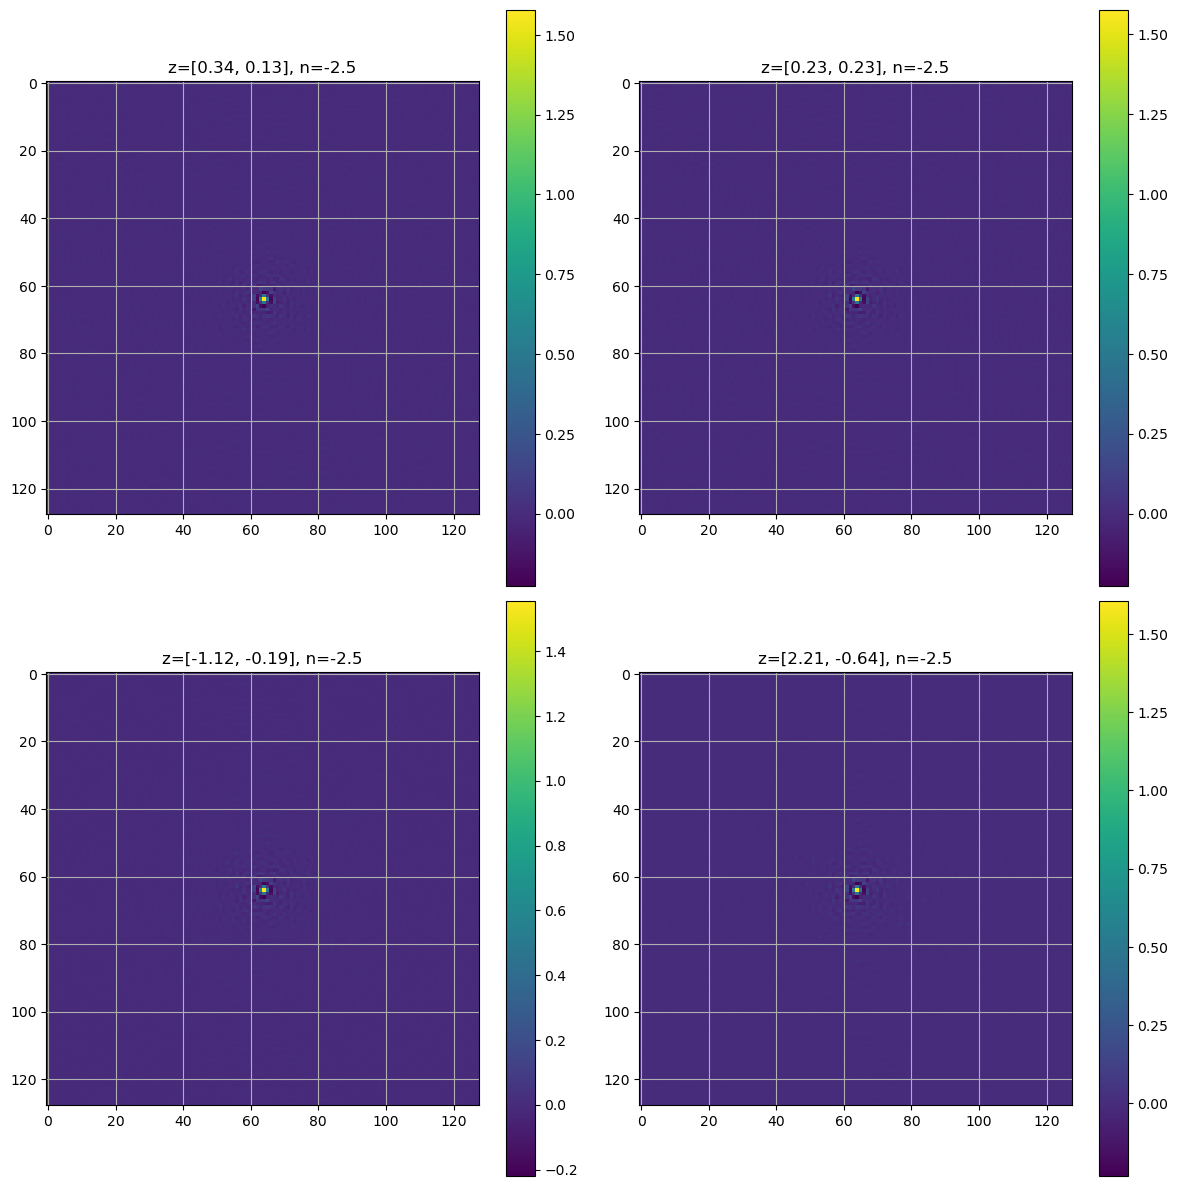

In [37]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x11full[i,0]))
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

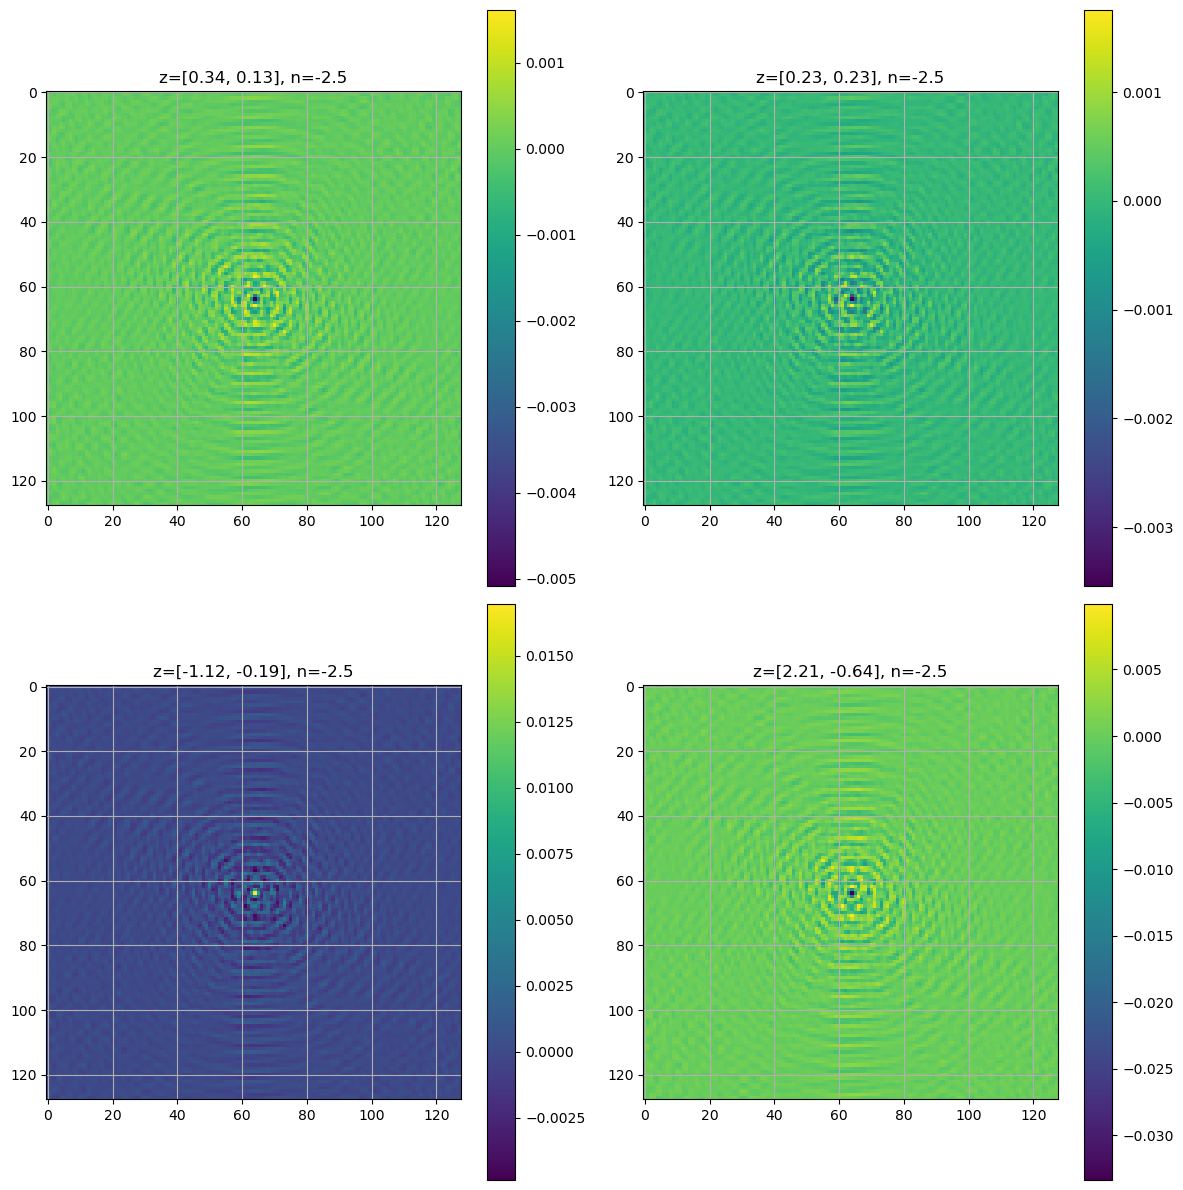

In [38]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))
for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()
    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(torch.real(x10full[i,0]-x11full[i,0]))
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

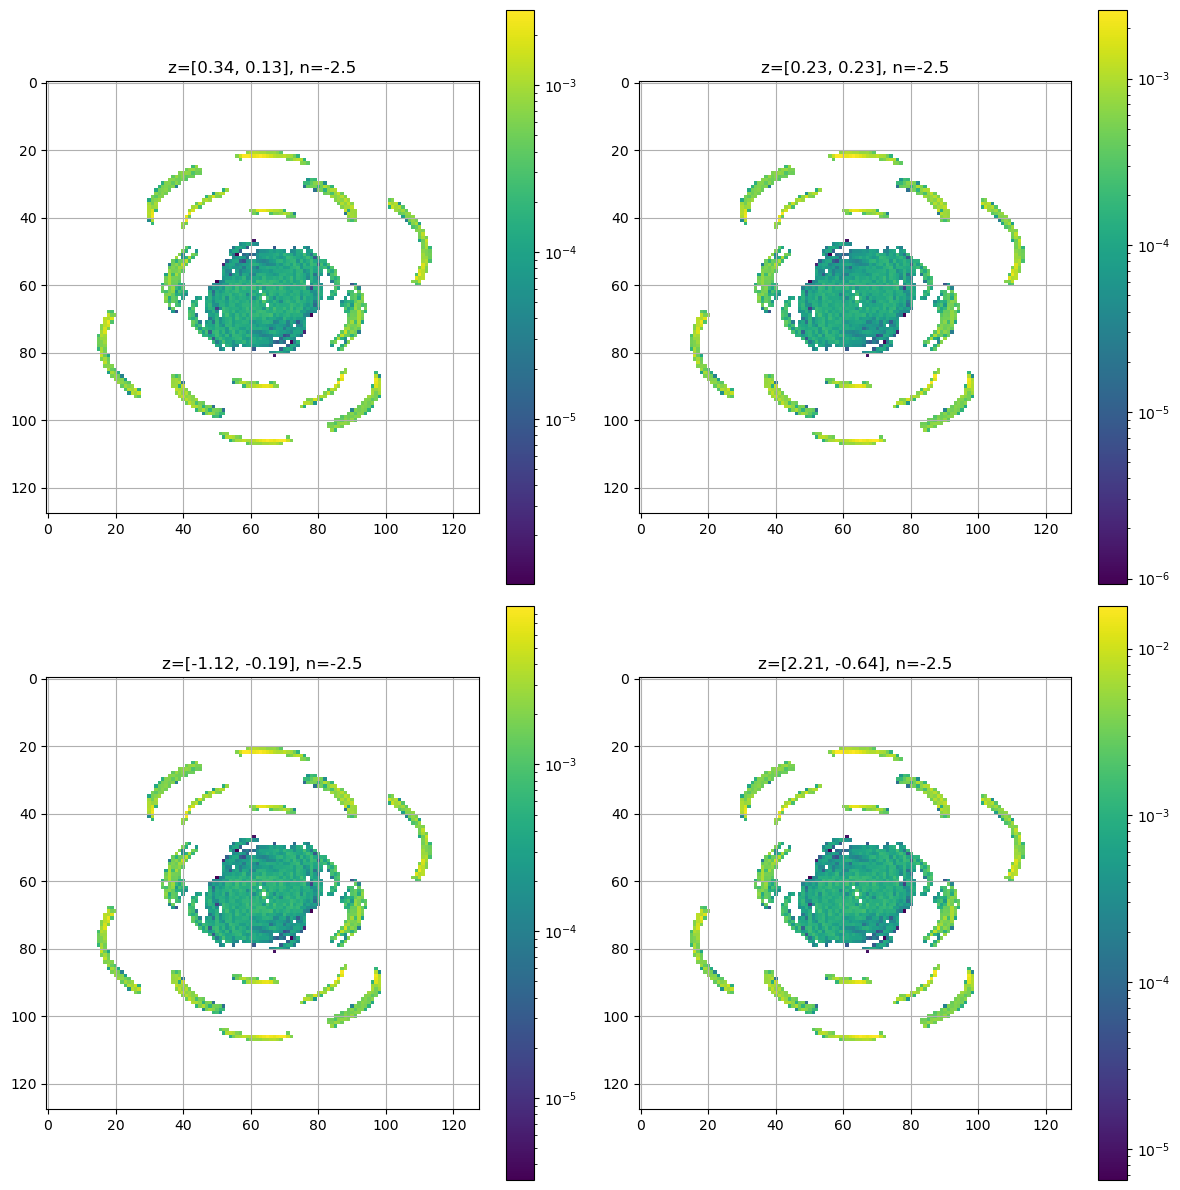

In [39]:
fig, axes = plt.subplots(B, B, figsize=(12, 12))

for i in range(B*B):
    row = i // B
    col = i % B
    a_val = a_flat[i].item()
    n_val = n_flat[i].item()

    
    # y = a_val * x**n_val  # example function
    
    # axes[row, col].imshow(x[i,0])
    im = axes[row, col].imshow(np.fft.fftshift(torch.abs(results10full["normed_tracked_uv"][i,0]-results11full["normed_tracked_uv"][i,0]).cpu().numpy()), norm=LogNorm())
    z_val = z[i, :4]  # first 4 z values

    z_str = ", ".join(f"{v:.2f}" for v in z_val)

    axes[row, col].set_title(f"z=[{z_str}], n={n_val:.1f}")
    axes[row, col].grid(True)
    plt.colorbar(im, ax=axes[row, col])
    # axes[row, col].colorbar()
plt.tight_layout()
plt.show()

In [40]:
results11full["normed_tracked_uv"][0,1]-results11full["normed_tracked_uv"][1,1]

tensor([[0.+0.j, 0.+0.j, 0.+0.j,  ..., 0.+0.j, 0.+0.j, 0.+0.j],
        [0.+0.j, 0.+0.j, 0.+0.j,  ..., 0.+0.j, 0.+0.j, 0.+0.j],
        [0.+0.j, 0.+0.j, 0.+0.j,  ..., 0.+0.j, 0.+0.j, 0.+0.j],
        ...,
        [0.+0.j, 0.+0.j, 0.+0.j,  ..., 0.+0.j, 0.+0.j, 0.+0.j],
        [0.+0.j, 0.+0.j, 0.+0.j,  ..., 0.+0.j, 0.+0.j, 0.+0.j],
        [0.+0.j, 0.+0.j, 0.+0.j,  ..., 0.+0.j, 0.+0.j, 0.+0.j]])

/scratch-local/jsanghavi1.28014762/ipykernel_3470155/2014822350.py:1: RuntimeWarning: invalid value encountered in divide
  implot = plt.imshow(np.fft.fftshift(torch.abs(results11full["normed_tracked_uv"][1,0]).cpu().numpy())/(np.fft.fftshift(torch.abs(results11full["normed_tracked_uv"][0,0]).cpu().numpy())))


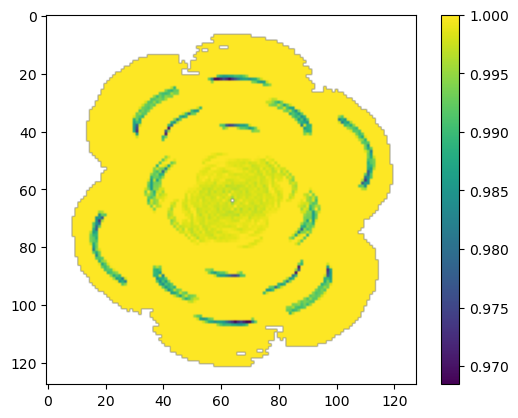

In [41]:
implot = plt.imshow(np.fft.fftshift(torch.abs(results11full["normed_tracked_uv"][1,0]).cpu().numpy())/(np.fft.fftshift(torch.abs(results11full["normed_tracked_uv"][0,0]).cpu().numpy())))
plt.colorbar(implot)